# Evaluasi Komparasi Lengkap: Multitask GABSA & Summarization (data_v4)

Jupyter Notebook ini digunakan untuk mengevaluasi secara komprehensif dan membandingkan performa model **Qwen2.5-3B-Instruct** sebelum dan sesudah fine-tuning pada data test set versi 4 (`data_v4`).

Model yang dibandingkan:
1. **Base Model (Zero-Shot)**: Model baseline Qwen2.5-3B-Instruct (4-bit) dengan prompt zero-shot.
2. **Base Model (Few-Shot)**: Model baseline Qwen2.5-3B-Instruct (4-bit) dengan prompt 2-shot.
3. **Fine-Tuned Model**: Model hasil multi-task fine-tuning GABSA & Summarization.

Evaluasi dilakukan pada 2 tugas utama:
- **Task A (GABSA)**: Aspect Extraction, Sentiment Extraction, Aspect-Sentiment Pair Extraction, Evidence Token Overlap Consistency, Sentiment Polarity Accuracy, ROC-AUC, Per-Aspect Breakdown, serta **Kepatuhan Format Output JSON** (Strict JSON Rate, Lenient JSON Rate, Total Valid Rate, dan Invalid Rate).
- **Task B (Summarization)**: Pembuatan ringkasan analitik strategis dari statistik agregat ulasan (ROUGE-1, ROUGE-2, ROUGE-L, BERTScore F1, dan Latensi).


## 0. Install Dependencies
Instalasi library tambahan untuk perhitungan ROUGE dan BERTScore jika dijalankan di Google Colab.


## 1. Imports & Environment Setup


In [1]:
import os
import json
import re
import time
import difflib
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from tqdm import tqdm

from sklearn.metrics import roc_auc_score
from rouge_score import rouge_scorer
from bert_score import score as bert_score_fn

# Pastikan grafik matplotlib ditampilkan secara inline
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("muted")

print("Libraries loaded successfully.")


Libraries loaded successfully.


## 2. Paths Configuration
Tentukan flag `IS_COLAB` untuk menyesuaikan path antara Google Colab dan local folder.


In [2]:
# Konfigurasi Path (Colab vs Local)
IS_COLAB = False  # Ubah ke True jika dijalankan di Google Colab

if IS_COLAB:
    DATA_DIR = "/content/drive/MyDrive/Skripsi/data_v4/"
    GABSA_GT_PATH = os.path.join(DATA_DIR, "data_split/gabsa_test.jsonl")
    SUMMARY_GT_PATH = os.path.join(DATA_DIR, "data_split/summary_test.xlsx")
    
    GABSA_PRED_ZERO = os.path.join(DATA_DIR, "gabsa_predictions_base_zero.jsonl")
    GABSA_PRED_FEW  = os.path.join(DATA_DIR, "gabsa_predictions_base_few.jsonl")
    GABSA_PRED_FT   = os.path.join(DATA_DIR, "gabsa_predictions_finetune.jsonl")
    
    SUMMARY_PRED_ZERO = os.path.join(DATA_DIR, "summary_predictions_base_zero.jsonl")
    SUMMARY_PRED_FEW  = os.path.join(DATA_DIR, "summary_predictions_base_few.jsonl")
    SUMMARY_PRED_FT   = os.path.join(DATA_DIR, "summary_predictions_finetune.jsonl")
    
    OUTPUT_DIR = os.path.join(DATA_DIR, "evaluation_results/")
else:
    GABSA_GT_PATH = "data_split/gabsa_test.jsonl"
    SUMMARY_GT_PATH = "data_split/summary_test.xlsx"
    
    GABSA_PRED_ZERO = "gabsa_predictions_base_zero.jsonl"
    GABSA_PRED_FEW  = "gabsa_predictions_base_few.jsonl"
    GABSA_PRED_FT   = "gabsa_predictions_finetune.jsonl"
    
    SUMMARY_PRED_ZERO = "summary_predictions_base_zero.jsonl"
    SUMMARY_PRED_FEW  = "summary_predictions_base_few.jsonl"
    SUMMARY_PRED_FT   = "summary_predictions_finetune.jsonl"
    
    OUTPUT_DIR = "evaluation_results/"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"GABSA Ground Truth: {GABSA_GT_PATH}")
print(f"Summary Ground Truth: {SUMMARY_GT_PATH}")
print(f"Output directory for plots: {OUTPUT_DIR}")


GABSA Ground Truth: data_split/gabsa_test.jsonl
Summary Ground Truth: data_split/summary_test.xlsx
Output directory for plots: evaluation_results/


## 3. Data Loading Functions


In [3]:
def load_jsonl(file_path):
    """Memuat file JSONL."""
    records = []
    with open(file_path, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                records.append(json.loads(line))
    return records

def load_summary_gt(file_path):
    """Memuat data ground truth summary dari Excel."""
    df = pd.read_excel(file_path)
    records = []
    for idx, row in df.iterrows():
        records.append({
            "input_stats": str(row["input_stats"]).strip(),
            "target_summary": str(row["target_summary"]).strip()
        })
    return records

# Load Ground Truth Data
try:
    gabsa_test_data = load_jsonl(GABSA_GT_PATH)
    summary_test_data = load_summary_gt(SUMMARY_GT_PATH)
    print(f"Loaded {len(gabsa_test_data)} GABSA test records.")
    print(f"Loaded {len(summary_test_data)} Summary test records.")
except Exception as e:
    print(f"Error loading ground truth files: {e}")


Loaded 1181 GABSA test records.
Loaded 15 Summary test records.


## 4. JSON Parsing & Comprehensive GABSA Evaluator
Fungsi `get_token_f1` menghitung token-level F1-score untuk bukti teks (*evidence*), `safe_parse_json` menguji dan menangani kepatuhan parsing JSON secara **Strict** (JSON murni langsung) dan **Lenient** (JSON terekstrak dari markdown block/regex), serta `evaluate_gabsa` mengukur Aspect, Sentiment, Pair, Evidence Overlap, ROC-AUC, Sentiment Polarity Accuracy, dan Per-Aspect Category breakdown.


In [4]:
def get_token_f1(ref_str, pred_str):
    """Menghitung token-level F1-score antara dua string bukti teks (evidence)."""
    if not isinstance(ref_str, str): ref_str = ""
    if not isinstance(pred_str, str): pred_str = ""
    ref_tokens = re.sub(r'[^\w\s]', '', ref_str.lower()).split()
    pred_tokens = re.sub(r'[^\w\s]', '', pred_str.lower()).split()
    if not ref_tokens and not pred_tokens: return 1.0
    if not ref_tokens or not pred_tokens: return 0.0
    ref_counter = Counter(ref_tokens)
    pred_counter = Counter(pred_tokens)
    overlap = sum((ref_counter & pred_counter).values())
    precision = overlap / len(pred_tokens)
    recall = overlap / len(ref_tokens)
    if precision + recall == 0: return 0.0
    return 2 * (precision * recall) / (precision + recall)

def safe_parse_json(content):
    """Parsing JSON dengan toleransi format (strict dan lenient)."""
    if not isinstance(content, str) or not content.strip():
        return [], False, False
    
    # 1. Strict Parsing
    try:
        data = json.loads(content.strip())
        is_valid_strict = False
        labels = []
        if isinstance(data, dict):
            if "labels" in data: 
                labels = data["labels"]
                is_valid_strict = isinstance(labels, list)
            elif "output" in data:
                labels = data["output"]
                is_valid_strict = isinstance(labels, list)
            elif "aspect" in data and "sentiment" in data and "evidence" in data:
                labels = [data]
                is_valid_strict = True
        elif isinstance(data, list):
            labels = data
            is_valid_strict = True
        
        if is_valid_strict:
            for item in labels:
                if not isinstance(item, dict) or "aspect" not in item or "sentiment" not in item or "evidence" not in item:
                    is_valid_strict = False
                    break
        if is_valid_strict:
            return labels, True, True
    except:
        pass
    
    # 2. Lenient Parsing (Regex Fallback)
    try:
        match = re.search(r'\{.*\}', content.strip(), re.DOTALL)
        if match:
            data = json.loads(match.group())
            labels = data.get("labels", data.get("output", []))
            if isinstance(labels, list):
                is_valid_lenient = True
                for item in labels:
                    if not isinstance(item, dict) or "aspect" not in item or "sentiment" not in item or "evidence" not in item:
                        is_valid_lenient = False
                        break
                if is_valid_lenient:
                    return labels, False, True
    except:
        pass
        
    try:
        match = re.search(r'\[.*\]', content.strip(), re.DOTALL)
        if match:
            data = json.loads(match.group())
            if isinstance(data, list):
                is_valid_lenient = True
                for item in data:
                    if not isinstance(item, dict) or "aspect" not in item or "sentiment" not in item or "evidence" not in item:
                        is_valid_lenient = False
                        break
                if is_valid_lenient:
                    return data, False, True
    except:
        pass
        
    return [], False, False

def evaluate_gabsa(test_records, parsed_predictions):
    """Menghitung Aspect, Sentiment, Pair Extraction, Evidence Overlap, ROC-AUC, dan Per-Aspect Category breakdown."""
    aspect_list = ["pelayanan", "fasilitas", "kebersihan", "waktu_tunggu", "administrasi", "tenaga_medis", "parkir_akses"]
    
    # Global Counts untuk 3 Jenis Ekstraksi
    tp_aspect, fp_aspect, fn_aspect = 0, 0, 0
    tp_sent, fp_sent, fn_sent = 0, 0, 0
    tp_pair, fp_pair, fn_pair = 0, 0, 0
    
    # Per-Aspect Counts & Ground Truth Support
    per_aspect = {a: {"tp": 0, "fp": 0, "fn": 0, "support": 0} for a in aspect_list}
    
    # Sentiment polarity check counts
    sentiment_correct = 0
    sentiment_total = 0
    
    # Evidence overlap arrays
    evidence_f1s_matched_pair = []
    evidence_f1s_matched_aspect = []
    evidence_f1s_global = []
    
    # Binary indicator matrix untuk ROC-AUC per-ulasan
    y_true_all = []
    y_pred_all = []
    
    for gt_item, pred_labels in zip(test_records, parsed_predictions):
        gt_labels = gt_item["labels"]
        
        # Aspect Extraction
        gt_aspects = {l["aspect"].strip().lower() for l in gt_labels if "aspect" in l and l["aspect"].strip().lower() in aspect_list}
        pred_aspects = {l["aspect"].strip().lower() for l in pred_labels if isinstance(l, dict) and "aspect" in l and l["aspect"].strip().lower() in aspect_list}
        
        # Sentiment Extraction
        gt_sents = {l["sentiment"].strip().lower() for l in gt_labels if "sentiment" in l and l.get("aspect", "").strip().lower() in aspect_list}
        pred_sents = {l["sentiment"].strip().lower() for l in pred_labels if isinstance(l, dict) and "sentiment" in l and l.get("aspect", "").strip().lower() in aspect_list}
        
        # Pair Extraction (Aspect + Sentiment)
        gt_pairs = {(l["aspect"].strip().lower(), l["sentiment"].strip().lower()) for l in gt_labels if "aspect" in l and "sentiment" in l and l["aspect"].strip().lower() in aspect_list}
        pred_pairs = {(l["aspect"].strip().lower(), l["sentiment"].strip().lower()) for l in pred_labels if isinstance(l, dict) and "aspect" in l and "sentiment" in l and l["aspect"].strip().lower() in aspect_list}
        
        # 1. Aspect Counts
        tp_aspect += len(gt_aspects & pred_aspects)
        fp_aspect += len(pred_aspects - gt_aspects)
        fn_aspect += len(gt_aspects - pred_aspects)
        
        for a in aspect_list:
            in_gt = a in gt_aspects
            in_pred = a in pred_aspects
            if in_gt: per_aspect[a]["support"] += 1
            if in_gt and in_pred: per_aspect[a]["tp"] += 1
            elif in_pred and not in_gt: per_aspect[a]["fp"] += 1
            elif in_gt and not in_pred: per_aspect[a]["fn"] += 1
            
        # 2. Sentiment Counts
        tp_sent += len(gt_sents & pred_sents)
        fp_sent += len(pred_sents - gt_sents)
        fn_sent += len(gt_sents - pred_sents)
        
        # 3. Pair Counts
        tp_pair += len(gt_pairs & pred_pairs)
        fp_pair += len(pred_pairs - gt_pairs)
        fn_pair += len(gt_pairs - pred_pairs)
        
        # 4. Sentiment Polarity check (pada aspek yang cocok)
        for aspect_name in (gt_aspects & pred_aspects):
            g_s = {p[1] for p in gt_pairs if p[0] == aspect_name}
            p_s = {p[1] for p in pred_pairs if p[0] == aspect_name}
            if g_s and p_s:
                sentiment_total += 1
                if (g_s & p_s):
                    sentiment_correct += 1
                    
        # 5. Evidence Overlap Calculation
        for gt_lbl in gt_labels:
            if not isinstance(gt_lbl, dict): continue
            gt_a = gt_lbl.get("aspect", "").strip().lower()
            gt_s = gt_lbl.get("sentiment", "").strip().lower()
            gt_e = gt_lbl.get("evidence", "")
            if gt_a not in aspect_list: continue
            
            matched_p = [p for p in pred_labels if isinstance(p, dict) and p.get("aspect", "").strip().lower() == gt_a and p.get("sentiment", "").strip().lower() == gt_s]
            if matched_p:
                evidence_f1s_matched_pair.append(max(get_token_f1(gt_e, p.get("evidence", "")) for p in matched_p))
                
            matched_a = [p for p in pred_labels if isinstance(p, dict) and p.get("aspect", "").strip().lower() == gt_a]
            if matched_a:
                evidence_f1s_matched_aspect.append(max(get_token_f1(gt_e, p.get("evidence", "")) for p in matched_a))
                
        gt_all_ev = " ".join([l.get("evidence", "") for l in gt_labels if isinstance(l, dict) and l.get("evidence")])
        pred_all_ev = " ".join([l.get("evidence", "") for l in pred_labels if isinstance(l, dict) and l.get("evidence")])
        evidence_f1s_global.append(get_token_f1(gt_all_ev, pred_all_ev))
        
        # ROC-AUC binary indicators (1=hadir, 0=absen)
        y_true_row = [1 if a in gt_aspects else 0 for a in aspect_list]
        y_pred_row = [1 if a in pred_aspects else 0 for a in aspect_list]
        y_true_all.append(y_true_row)
        y_pred_all.append(y_pred_row)
        
    # Precision, Recall, F1 calculation helper
    def calc_prf(tp, fp, fn):
        p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
        return p, r, f
        
    p_a, r_a, f_a = calc_prf(tp_aspect, fp_aspect, fn_aspect)
    p_s, r_s, f_s = calc_prf(tp_sent, fp_sent, fn_sent)
    p_p, r_p, f_p = calc_prf(tp_pair, fp_pair, fn_pair)
    sent_acc = sentiment_correct / sentiment_total if sentiment_total > 0 else 0.0
    
    # Multi-label ROC-AUC
    y_true_all = np.array(y_true_all)
    y_pred_all = np.array(y_pred_all)
    try:
        roc_auc = roc_auc_score(y_true_all, y_pred_all, average="macro", multi_class="ovr")
    except:
        roc_auc = 0.5
        
    # Per-aspect detailed metrics (Precision, Recall, F1, Support)
    per_aspect_detail = {}
    per_aspect_f1 = {}
    for a in aspect_list:
        p_val, r_val, f_val = calc_prf(per_aspect[a]["tp"], per_aspect[a]["fp"], per_aspect[a]["fn"])
        per_aspect_f1[a] = f_val
        per_aspect_detail[a] = {
            "precision": p_val,
            "recall": r_val,
            "f1": f_val,
            "support": per_aspect[a]["support"]
        }
        
    avg_ev_pair = float(np.mean(evidence_f1s_matched_pair)) if evidence_f1s_matched_pair else 0.0
    avg_ev_aspect = float(np.mean(evidence_f1s_matched_aspect)) if evidence_f1s_matched_aspect else 0.0
    avg_ev_global = float(np.mean(evidence_f1s_global)) if evidence_f1s_global else 0.0
    
    return {
        "aspect_precision": p_a, "aspect_recall": r_a, "aspect_f1": f_a,
        "sentiment_precision": p_s, "sentiment_recall": r_s, "sentiment_f1": f_s,
        "pair_precision": p_p, "pair_recall": r_p, "pair_f1": f_p,
        "sentiment_accuracy": sent_acc,
        "evidence_pair_f1": avg_ev_pair,
        "evidence_aspect_f1": avg_ev_aspect,
        "evidence_global_f1": avg_ev_global,
        "evidence_global_list": evidence_f1s_global,
        "roc_auc": roc_auc,
        "per_aspect_f1": per_aspect_f1,
        "per_aspect_detail": per_aspect_detail
    }


## 5. Summarization Evaluator
Menghitung skor ROUGE-1, ROUGE-2, ROUGE-L, dan BERTScore (F1) untuk mengukur kualitas laporan analitik strategis.


In [5]:
def evaluate_summary(predictions):
    """Menghitung ROUGE-1, 2, L dan BERTScore F1."""
    scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=False)
    
    r1_scores = []
    r2_scores = []
    rl_scores = []
    
    preds = []
    refs = []
    
    for item in predictions:
        ref = item.get("target_summary", item.get("reference_summary", "")).strip()
        pred = item.get("prediction_raw", item.get("predicted_summary", "")).strip()
        
        preds.append(pred)
        refs.append(ref)
        
        scores = scorer.score(ref, pred)
        r1_scores.append(scores["rouge1"].fmeasure)
        r2_scores.append(scores["rouge2"].fmeasure)
        rl_scores.append(scores["rougeL"].fmeasure)
        
    # Hitung BERTScore
    print("Calculating BERTScore (lang=id)... (This might take a moment)")
    try:
        P, R, F1 = bert_score_fn(preds, refs, lang="id", verbose=False)
        avg_bert_f1 = float(torch.mean(F1).item()) if hasattr(F1, 'device') else float(np.mean(F1))
        avg_bert_p = float(torch.mean(P).item()) if hasattr(P, 'device') else float(np.mean(P))
        avg_bert_r = float(torch.mean(R).item()) if hasattr(R, 'device') else float(np.mean(R))
    except Exception as e:
        print(f"BERTScore Calculation skipped/failed: {e}")
        avg_bert_f1, avg_bert_p, avg_bert_r = 0.0, 0.0, 0.0
        
    return {
        "rouge1": np.mean(r1_scores),
        "rouge2": np.mean(r2_scores),
        "rougeL": np.mean(rl_scores),
        "bert_precision": avg_bert_p,
        "bert_recall": avg_bert_r,
        "bert_f1": avg_bert_f1
    }


## 6. Load Predictions & Run Metric Calculations
Memuat file prediksi dari masing-masing model (Zero-Shot, Few-Shot, dan Fine-Tuned) untuk dievaluasi secara serentak, serta menghitung metrik kepatuhan format output JSON (Strict, Lenient, Total Valid, dan Invalid Rate).


In [6]:
models = ["Base (Zero-Shot)", "Base (Few-Shot)", "Fine-Tuned"]

gabsa_pred_files = [GABSA_PRED_ZERO, GABSA_PRED_FEW, GABSA_PRED_FT]
summary_pred_files = [SUMMARY_PRED_ZERO, SUMMARY_PRED_FEW, SUMMARY_PRED_FT]

# --- Hitung Metrik Task A (GABSA) ---
eval_gabsa_results = {}
for name, file_path in zip(models, gabsa_pred_files):
    try:
        preds = load_jsonl(file_path)
        parsed_labels = []
        strict_valid = 0
        lenient_only = 0
        invalid_count = 0
        
        is_finetuned = ("finetune" in file_path.lower() or "ft" in name.lower())
        
        for item in preds:
            if is_finetuned and "predicted_labels" in item:
                lbls = item["predicted_labels"]
                strict_valid += 1
                parsed_labels.append(lbls)
            else:
                raw_pred = item.get("prediction_raw", "")
                lbls, strict, lenient = safe_parse_json(raw_pred)
                if strict:
                    strict_valid += 1
                elif lenient:
                    lenient_only += 1
                else:
                    invalid_count += 1
                parsed_labels.append(lbls)
            
        metrics = evaluate_gabsa(gabsa_test_data, parsed_labels)
        total_preds = len(preds)
        total_valid = strict_valid + lenient_only
        
        metrics["strict_json_rate"] = strict_valid / total_preds
        metrics["lenient_json_rate"] = lenient_only / total_preds
        metrics["total_json_rate"] = total_valid / total_preds
        metrics["invalid_json_rate"] = invalid_count / total_preds
        
        latency_vals = [item["inference_time_sec"] for item in preds if "inference_time_sec" in item]
        metrics["avg_latency"] = np.mean(latency_vals) if latency_vals else np.nan
        
        eval_gabsa_results[name] = metrics
        print(f"[GABSA] {name} calculated successfully.")
    except Exception as e:
        print(f"[GABSA] Failed to calculate {name}: {e}")
        import traceback
        traceback.print_exc()

# --- Hitung Metrik Task B (Summarization) ---
eval_summary_results = {}
for name, file_path in zip(models, summary_pred_files):
    try:
        preds = load_jsonl(file_path)
        metrics = evaluate_summary(preds)
        
        latency_vals = [item["inference_time_sec"] for item in preds if "inference_time_sec" in item]
        metrics["avg_latency"] = np.mean(latency_vals) if latency_vals else np.nan
        
        eval_summary_results[name] = metrics
        print(f"[Summary] {name} calculated successfully.")
    except Exception as e:
        print(f"[Summary] Failed to calculate {name}: {e}")
        import traceback
        traceback.print_exc()


[GABSA] Base (Zero-Shot) calculated successfully.
[GABSA] Base (Few-Shot) calculated successfully.
[GABSA] Fine-Tuned calculated successfully.
Calculating BERTScore (lang=id)... (This might take a moment)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[Summary] Base (Zero-Shot) calculated successfully.
Calculating BERTScore (lang=id)... (This might take a moment)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[Summary] Base (Few-Shot) calculated successfully.
Calculating BERTScore (lang=id)... (This might take a moment)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[Summary] Fine-Tuned calculated successfully.


## 7. Display Results Comparison Tables
Menyusun perbandingan performa model ke dalam tabel komparatif lengkap, **Tabel Evaluasi Kepatuhan Format Output JSON**, serta tabel evaluasi **Per-Kategori Aspek Layanan** untuk model Fine-Tuned.


In [7]:
# GABSA comparison dataframe dengan Evidence Overlap & Kepatuhan JSON
gabsa_compare_df = pd.DataFrame({
    "Model Configuration": eval_gabsa_results.keys(),
    "JSON Validation (Strict)": [m["strict_json_rate"] for m in eval_gabsa_results.values()],
    "JSON Validation (Total Valid)": [m["total_json_rate"] for m in eval_gabsa_results.values()],
    "Aspect Extraction (F1)": [m["aspect_f1"] for m in eval_gabsa_results.values()],
    "Sentiment Extraction (F1)": [m["sentiment_f1"] for m in eval_gabsa_results.values()],
    "Pair Extraction (F1)": [m["pair_f1"] for m in eval_gabsa_results.values()],
    "Evidence Overlap (Matched Pair)": [m["evidence_pair_f1"] for m in eval_gabsa_results.values()],
    "Evidence Overlap (Matched Aspect)": [m["evidence_aspect_f1"] for m in eval_gabsa_results.values()],
    "Evidence Overlap (Global Review)": [m["evidence_global_f1"] for m in eval_gabsa_results.values()],
    "Sentiment Polarity Accuracy": [m["sentiment_accuracy"] for m in eval_gabsa_results.values()],
    "Aspect ROC-AUC Score": [m["roc_auc"] for m in eval_gabsa_results.values()]
})

# Tabel khusus Kepatuhan Format Output JSON
json_compliance_df = pd.DataFrame({
    "Model Configuration": eval_gabsa_results.keys(),
    "Strict JSON Rate (Direct)": [m["strict_json_rate"] for m in eval_gabsa_results.values()],
    "Lenient-Only Rate (Regex/Codeblock)": [m["lenient_json_rate"] for m in eval_gabsa_results.values()],
    "Total Valid JSON Rate": [m["total_json_rate"] for m in eval_gabsa_results.values()],
    "Invalid Format Rate (Failure)": [m["invalid_json_rate"] for m in eval_gabsa_results.values()]
})

# Summarization comparison dataframe
summary_compare_df = pd.DataFrame({
    "Model Configuration": eval_summary_results.keys(),
    "ROUGE-1 F-Measure": [m["rouge1"] for m in eval_summary_results.values()],
    "ROUGE-2 F-Measure": [m["rouge2"] for m in eval_summary_results.values()],
    "ROUGE-L F-Measure": [m["rougeL"] for m in eval_summary_results.values()],
    "BERTScore Precision": [m["bert_precision"] for m in eval_summary_results.values()],
    "BERTScore Recall": [m["bert_recall"] for m in eval_summary_results.values()],
    "BERTScore F1-Score": [m["bert_f1"] for m in eval_summary_results.values()],
    "Average Latency (seconds)": [m["avg_latency"] for m in eval_summary_results.values()]
})

print("=== TABEL PERBANDINGAN KOMPARATIF MODEL ===")
print("\n--- Task A (GABSA) Overall Performance Table:")
display(gabsa_compare_df.style.format({
    "JSON Validation (Strict)": "{:.2%}",
    "JSON Validation (Total Valid)": "{:.2%}",
    "Aspect Extraction (F1)": "{:.2%}",
    "Sentiment Extraction (F1)": "{:.2%}",
    "Pair Extraction (F1)": "{:.2%}",
    "Evidence Overlap (Matched Pair)": "{:.2%}",
    "Evidence Overlap (Matched Aspect)": "{:.2%}",
    "Evidence Overlap (Global Review)": "{:.2%}",
    "Sentiment Polarity Accuracy": "{:.2%}",
    "Aspect ROC-AUC Score": "{:.4f}"
}))

print("\n--- Rincian Kepatuhan Format Output JSON (Task A - GABSA):")
display(json_compliance_df.style.format({
    "Strict JSON Rate (Direct)": "{:.2%}",
    "Lenient-Only Rate (Regex/Codeblock)": "{:.2%}",
    "Total Valid JSON Rate": "{:.2%}",
    "Invalid Format Rate (Failure)": "{:.2%}"
}))

print("\n--- Task B (Summarization) Performance Table:")
display(summary_compare_df.style.format({
    "ROUGE-1 F-Measure": "{:.4f}",
    "ROUGE-2 F-Measure": "{:.4f}",
    "ROUGE-L F-Measure": "{:.4f}",
    "BERTScore Precision": "{:.4f}",
    "BERTScore Recall": "{:.4f}",
    "BERTScore F1-Score": "{:.4f}",
    "Average Latency (seconds)": "{:.2f}s"
}))

# --- Tabel Detail Rincian Per-Kategori Aspek Layanan (Fine-Tuned Model) ---
ft_aspect_detail = eval_gabsa_results["Fine-Tuned"]["per_aspect_detail"]
aspect_rows = []
precs, recs, f1s, total_sup = [], [], [], 0

for asp_name, det in ft_aspect_detail.items():
    aspect_rows.append({
        "Kategori Aspek Layanan": asp_name,
        "Precision (%)": det["precision"],
        "Recall (%)": det["recall"],
        "F1-Score (%)": det["f1"],
        "Jumlah Data": det["support"]
    })
    precs.append(det["precision"])
    recs.append(det["recall"])
    f1s.append(det["f1"])
    total_sup += det["support"]

# Tambahkan baris Rata-rata Makro
aspect_rows.append({
    "Kategori Aspek Layanan": "Rata-rata Makro",
    "Precision (%)": np.mean(precs),
    "Recall (%)": np.mean(recs),
    "F1-Score (%)": np.mean(f1s),
    "Jumlah Data": total_sup
})

per_aspect_table_df = pd.DataFrame(aspect_rows)

print("\n=== TABEL PER-KATEGORI ASPEK LAYANAN (FINE-TUNED MODEL) ===")
display(per_aspect_table_df.style.format({
    "Precision (%)": "{:.2%}",
    "Recall (%)": "{:.2%}",
    "F1-Score (%)": "{:.2%}",
    "Jumlah Data": "{:,}"
}))


=== TABEL PERBANDINGAN KOMPARATIF MODEL ===

--- Task A (GABSA) Overall Performance Table:


,Model Configuration,JSON Validation (Strict),JSON Validation (Total Valid),Aspect Extraction (F1),Sentiment Extraction (F1),Pair Extraction (F1),Evidence Overlap (Matched Pair),Evidence Overlap (Matched Aspect),Evidence Overlap (Global Review),Sentiment Polarity Accuracy,Aspect ROC-AUC Score
0,Base (Zero-Shot),4.06%,98.22%,59.44%,91.11%,56.19%,63.62%,62.55%,62.27%,94.97%,0.7229
1,Base (Few-Shot),89.75%,91.02%,57.37%,87.92%,54.46%,70.78%,69.88%,63.94%,95.91%,0.7189
2,Fine-Tuned,100.00%,100.00%,79.32%,95.94%,77.07%,79.29%,78.64%,76.75%,97.76%,0.8575



--- Rincian Kepatuhan Format Output JSON (Task A - GABSA):


,Model Configuration,Strict JSON Rate (Direct),Lenient-Only Rate (Regex/Codeblock),Total Valid JSON Rate,Invalid Format Rate (Failure)
0,Base (Zero-Shot),4.06%,94.16%,98.22%,1.78%
1,Base (Few-Shot),89.75%,1.27%,91.02%,8.98%
2,Fine-Tuned,100.00%,0.00%,100.00%,0.00%



--- Task B (Summarization) Performance Table:


,Model Configuration,ROUGE-1 F-Measure,ROUGE-2 F-Measure,ROUGE-L F-Measure,BERTScore Precision,BERTScore Recall,BERTScore F1-Score,Average Latency (seconds)
0,Base (Zero-Shot),0.2760,0.0535,0.1620,0.6911,0.7088,0.6997,26.37s
1,Base (Few-Shot),0.3104,0.0622,0.1851,0.7345,0.7162,0.7251,14.64s
2,Fine-Tuned,0.4446,0.1391,0.2972,0.7834,0.7799,0.7816,nans



=== TABEL PER-KATEGORI ASPEK LAYANAN (FINE-TUNED MODEL) ===


,Kategori Aspek Layanan,Precision (%),Recall (%),F1-Score (%),Jumlah Data
0,pelayanan,88.76%,80.20%,84.27%,591
1,fasilitas,70.83%,65.38%,68.00%,156
2,kebersihan,85.14%,88.73%,86.90%,142
3,waktu_tunggu,85.46%,87.01%,86.23%,331
4,administrasi,60.14%,63.12%,61.59%,141
5,tenaga_medis,68.87%,79.82%,73.94%,327
6,parkir_akses,78.85%,78.85%,78.85%,52
7,Rata-rata Makro,76.86%,77.59%,77.11%,"1,740"


## 8. Performance Visualization Plots
Menghasilkan visualisasi barchart perbandingan kepatuhan format output JSON (Strict vs Lenient vs Invalid), perbandingan performa 3 jenis ekstraksi GABSA, distribusi token overlap F1 untuk **Evidence Overlap** pada model Fine-Tuning, grafik komparasi Evidence Overlap, ROC-AUC & Sentiment Accuracy, serta metrik Summarization.


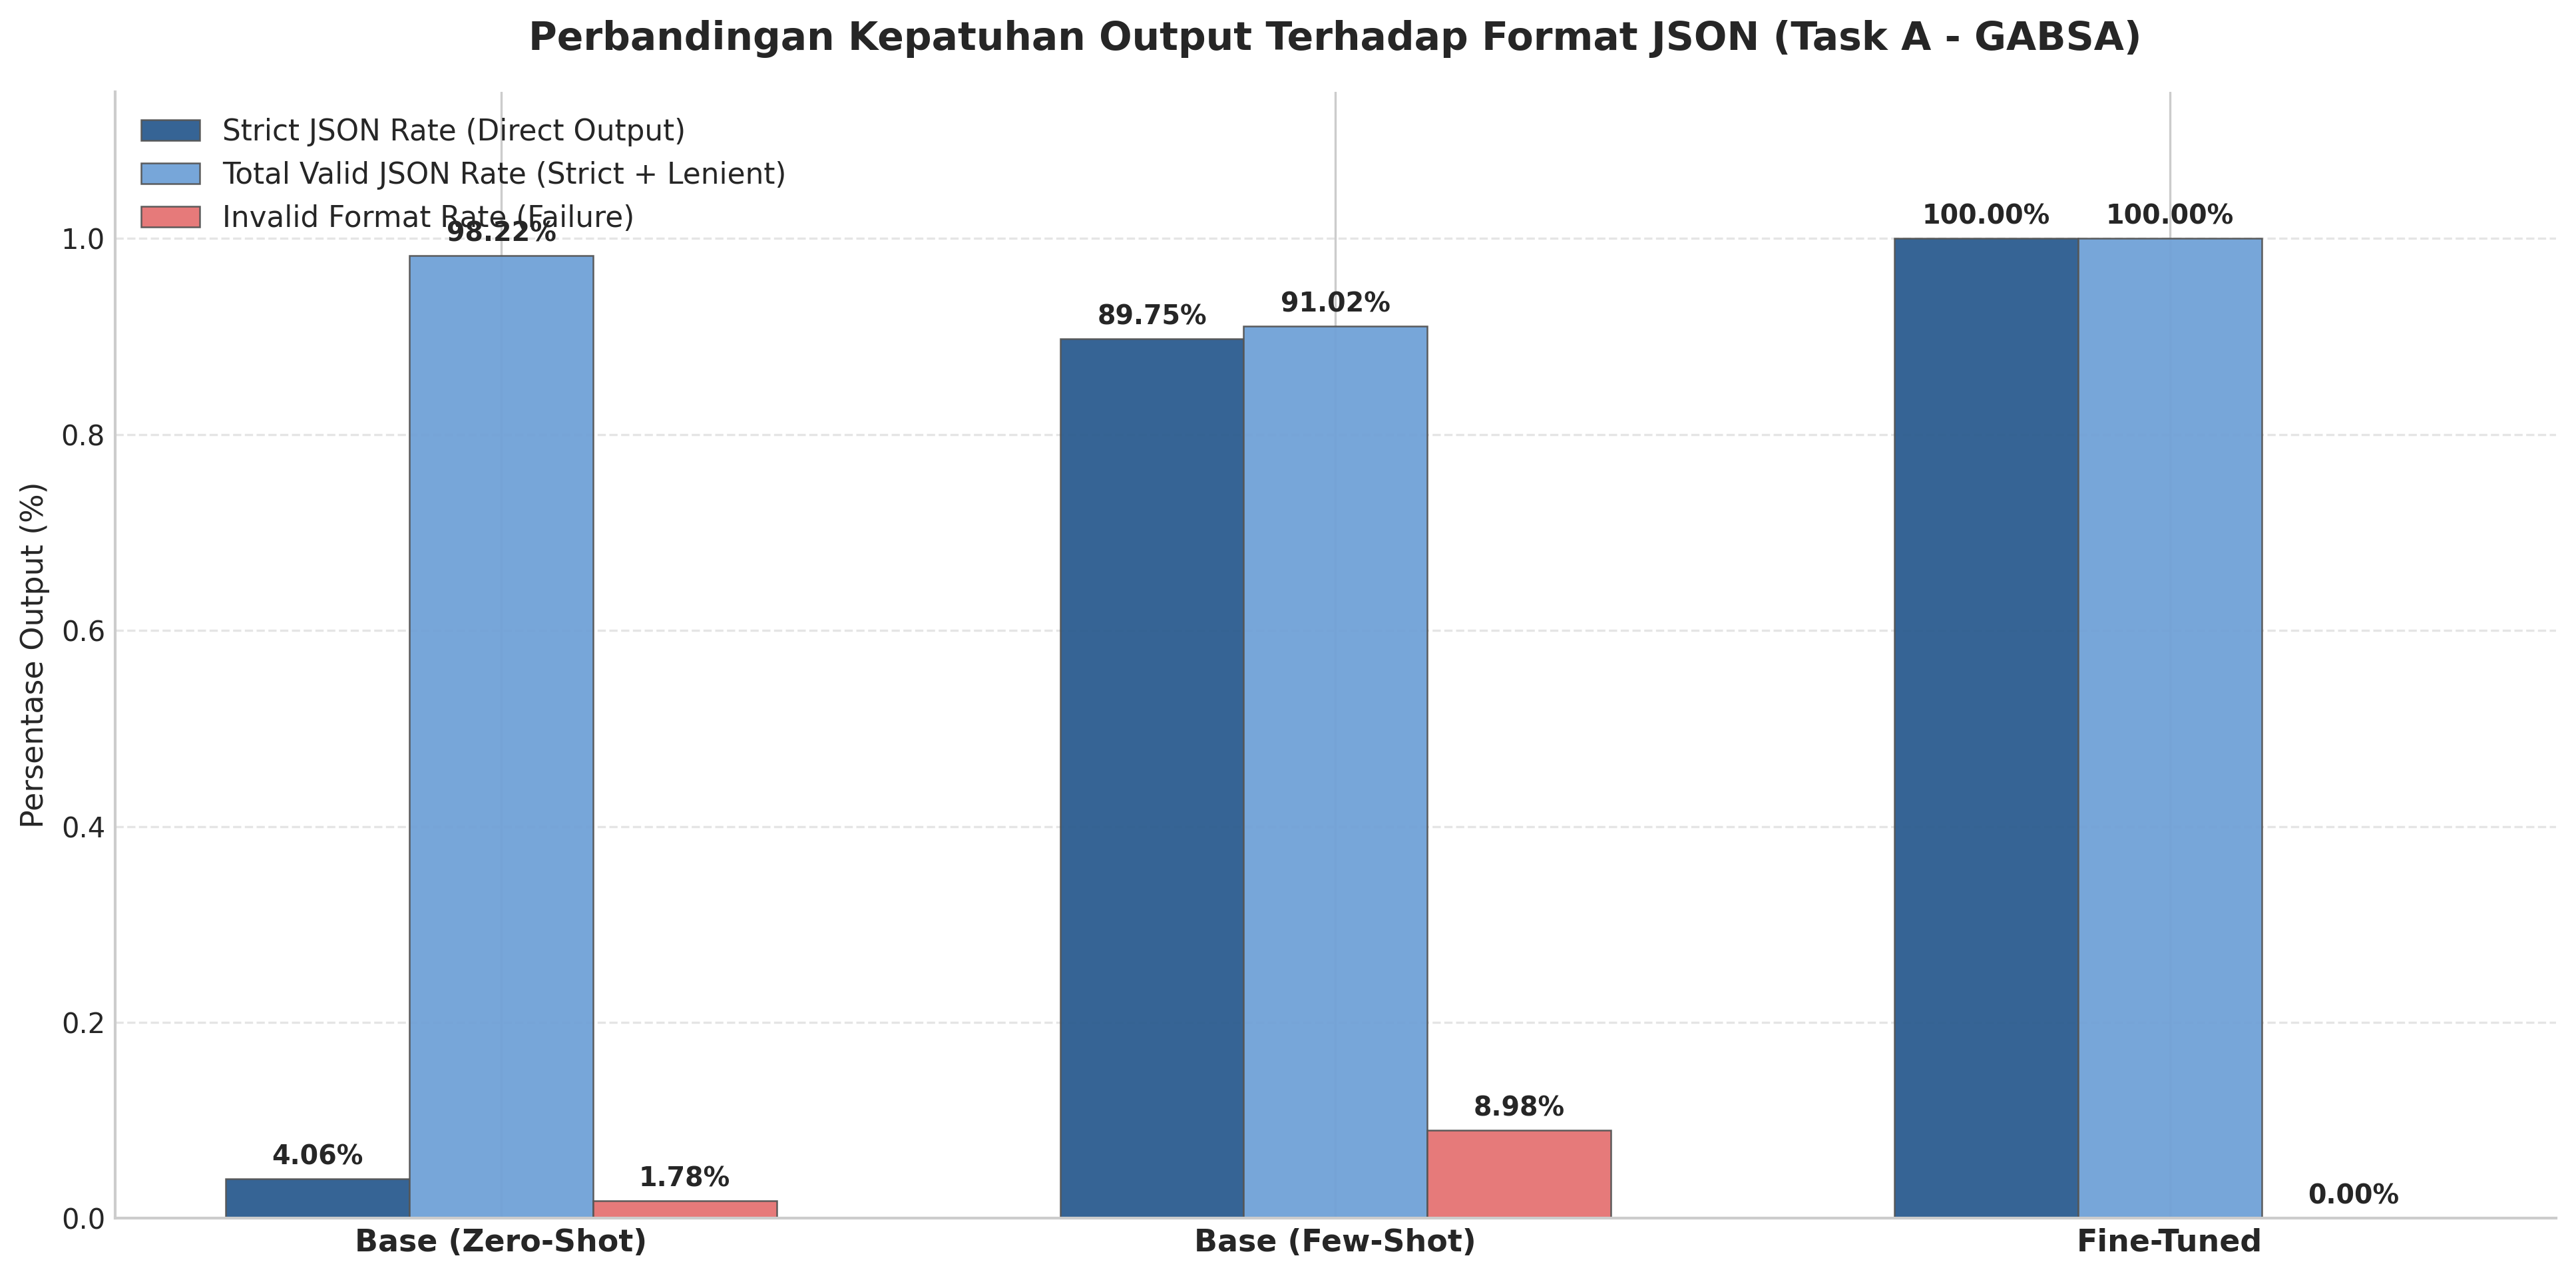

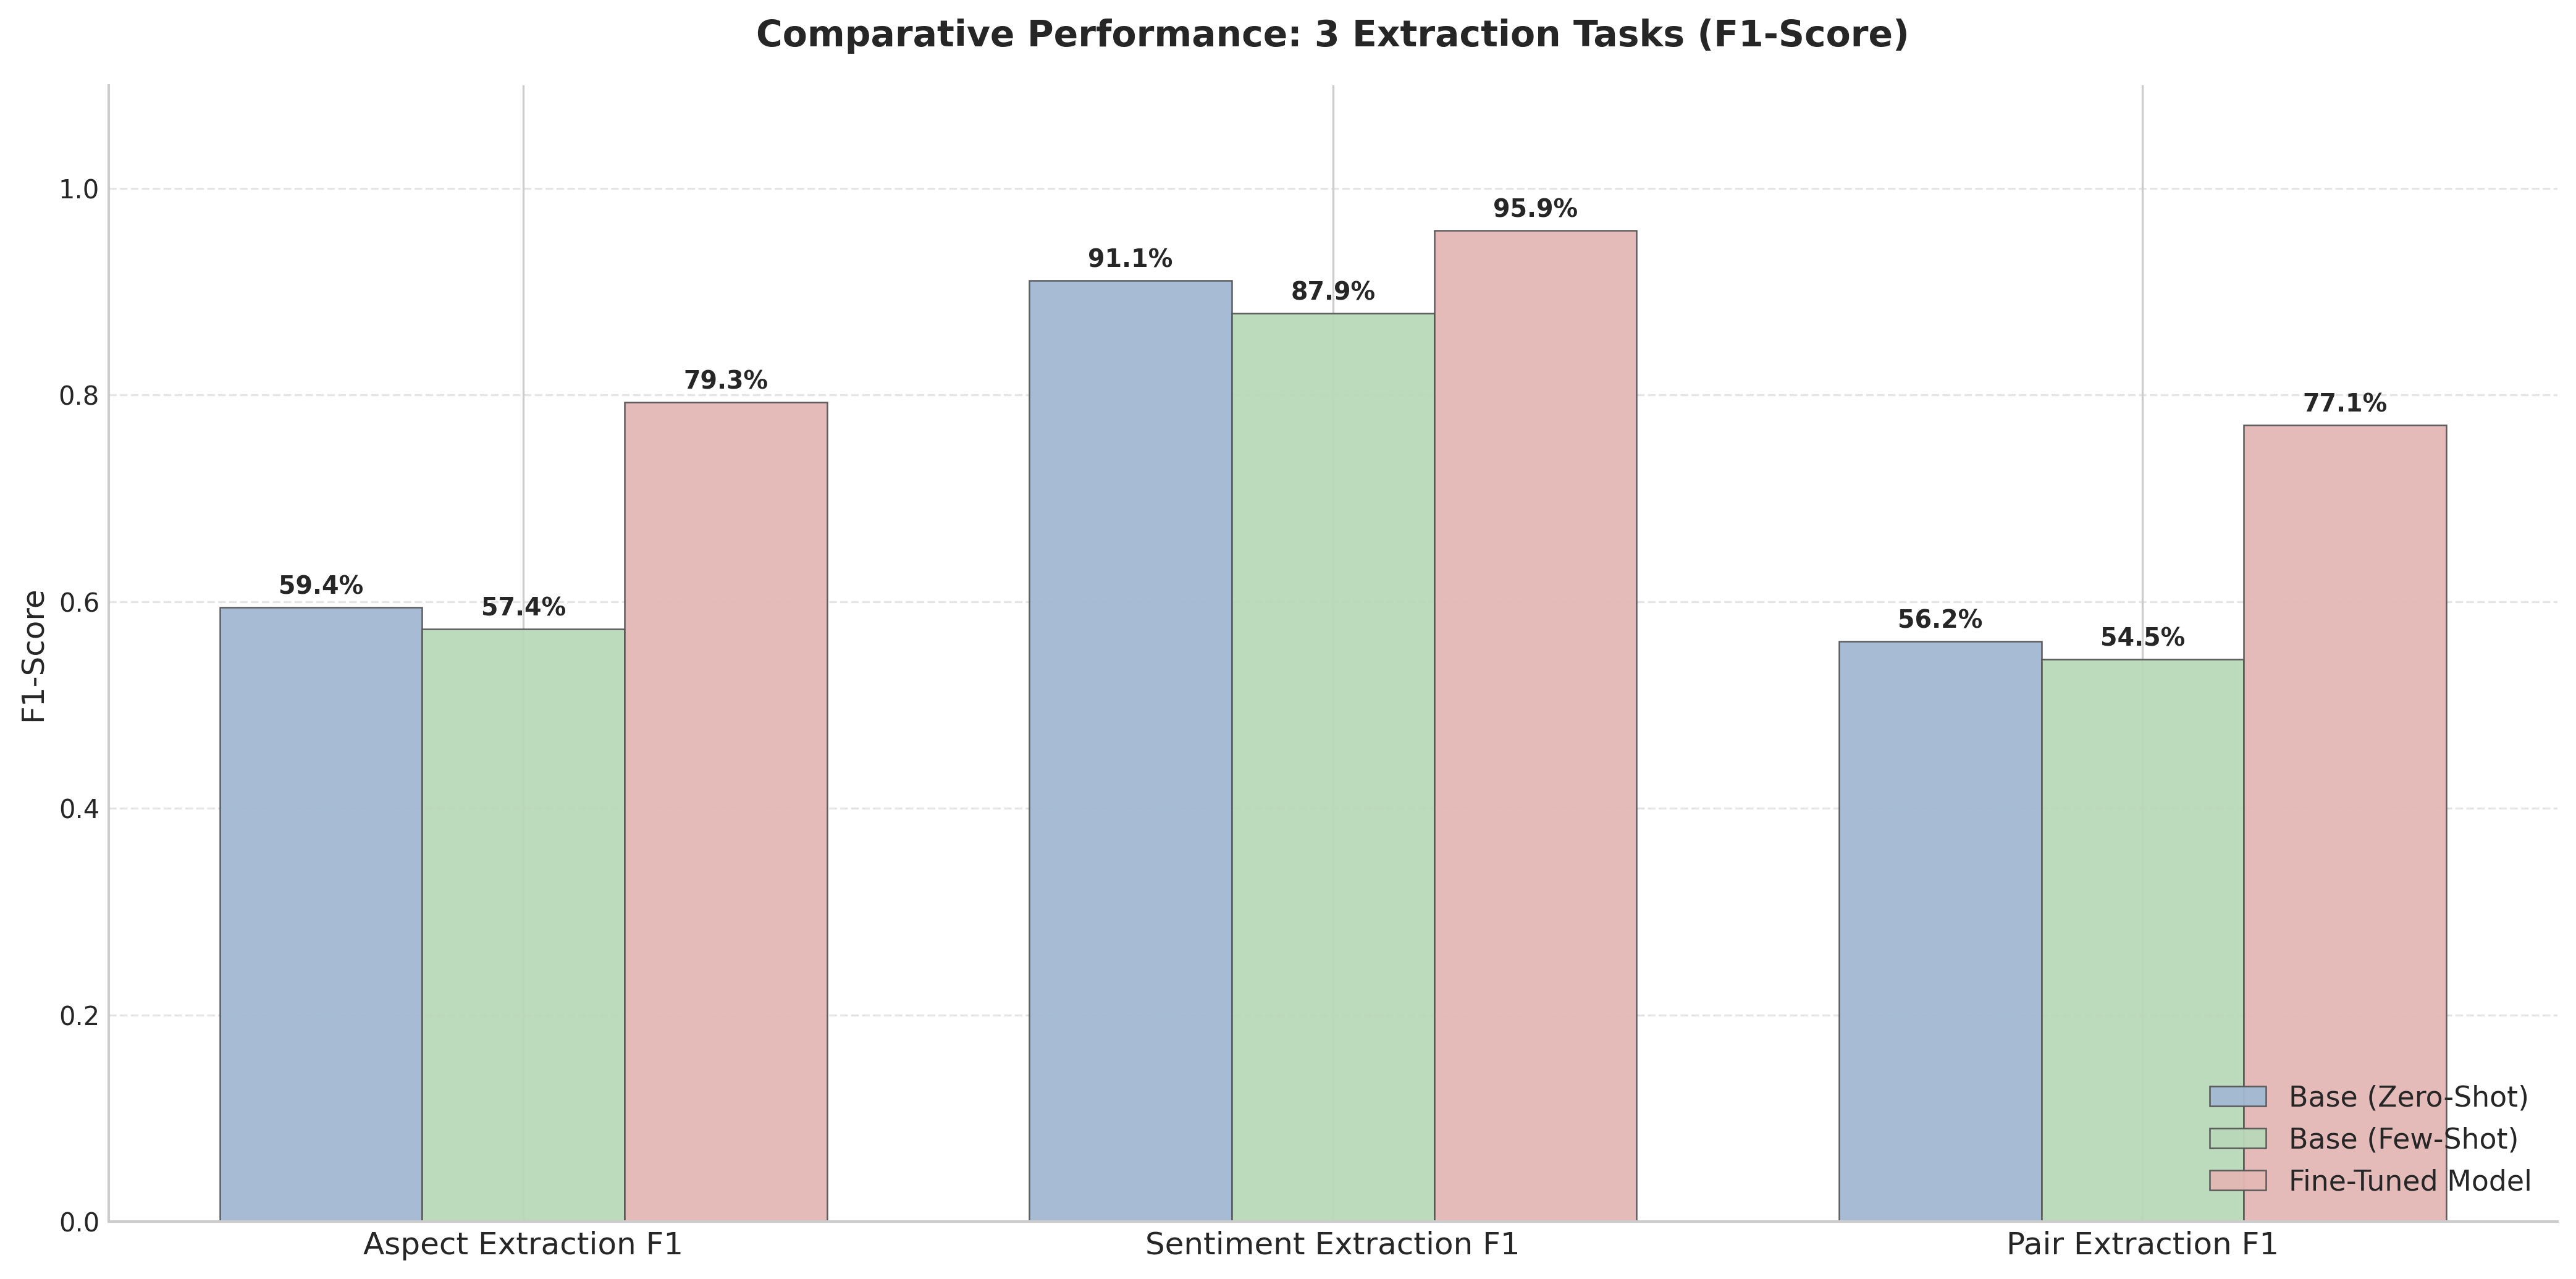

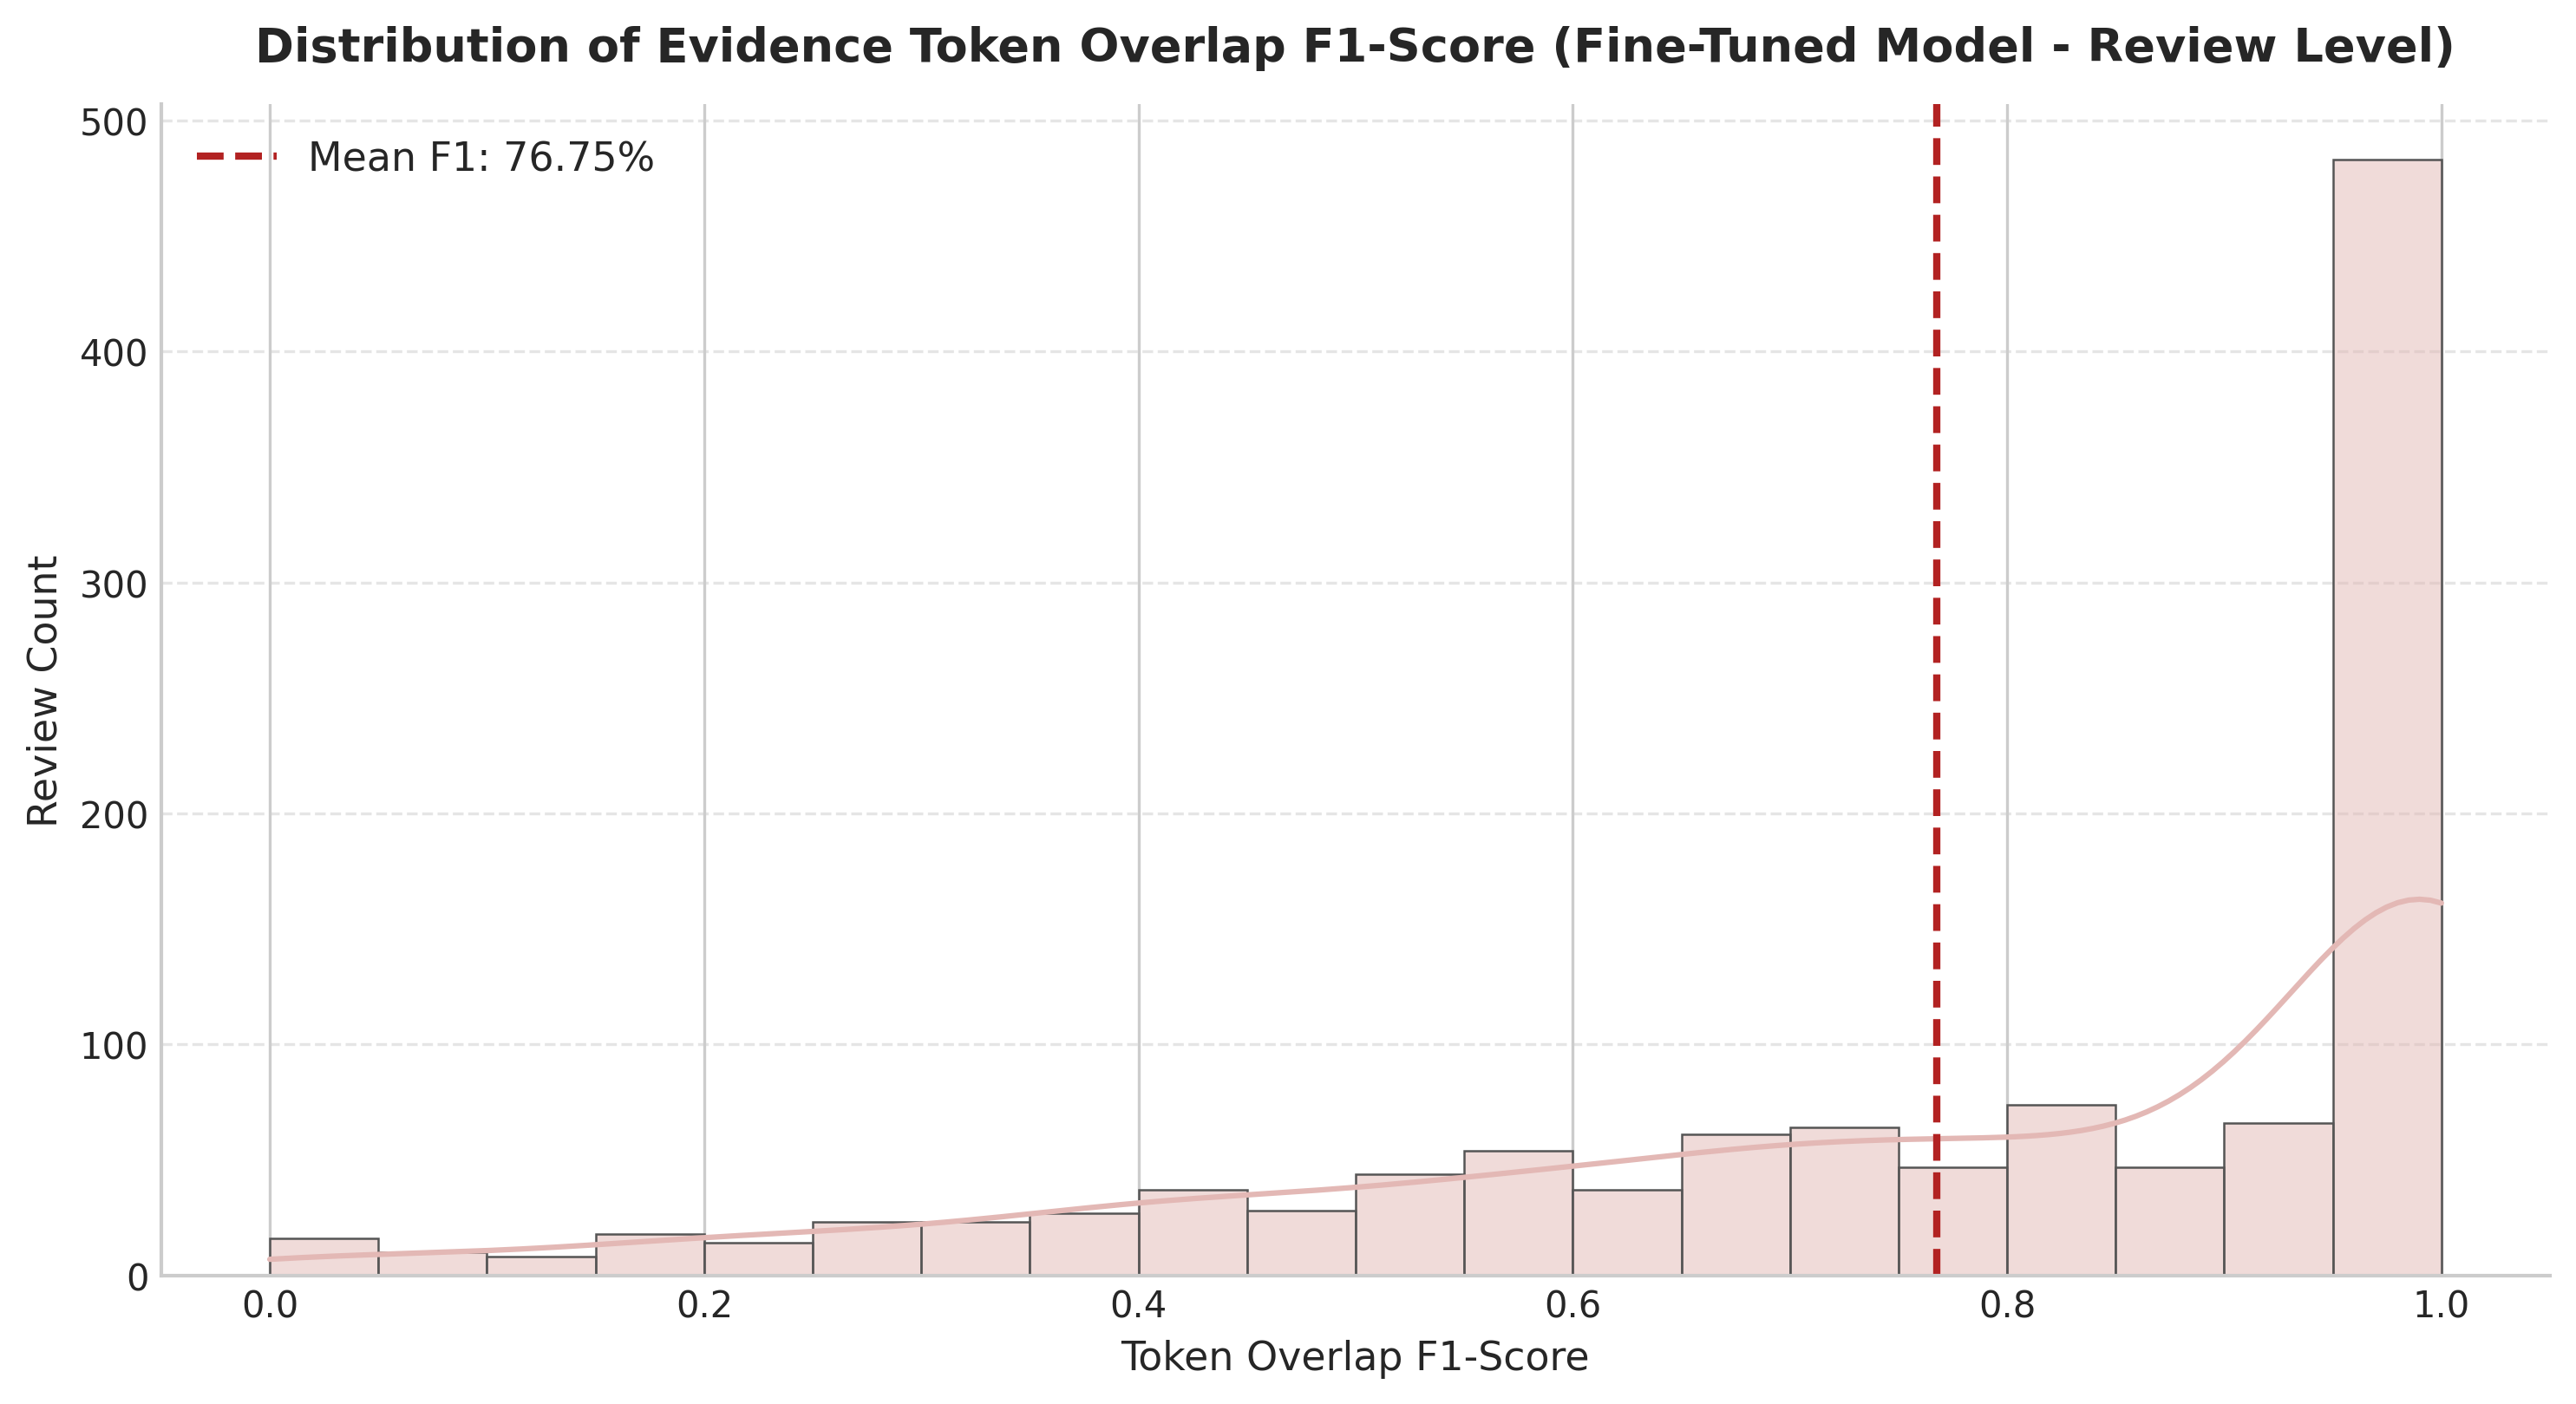

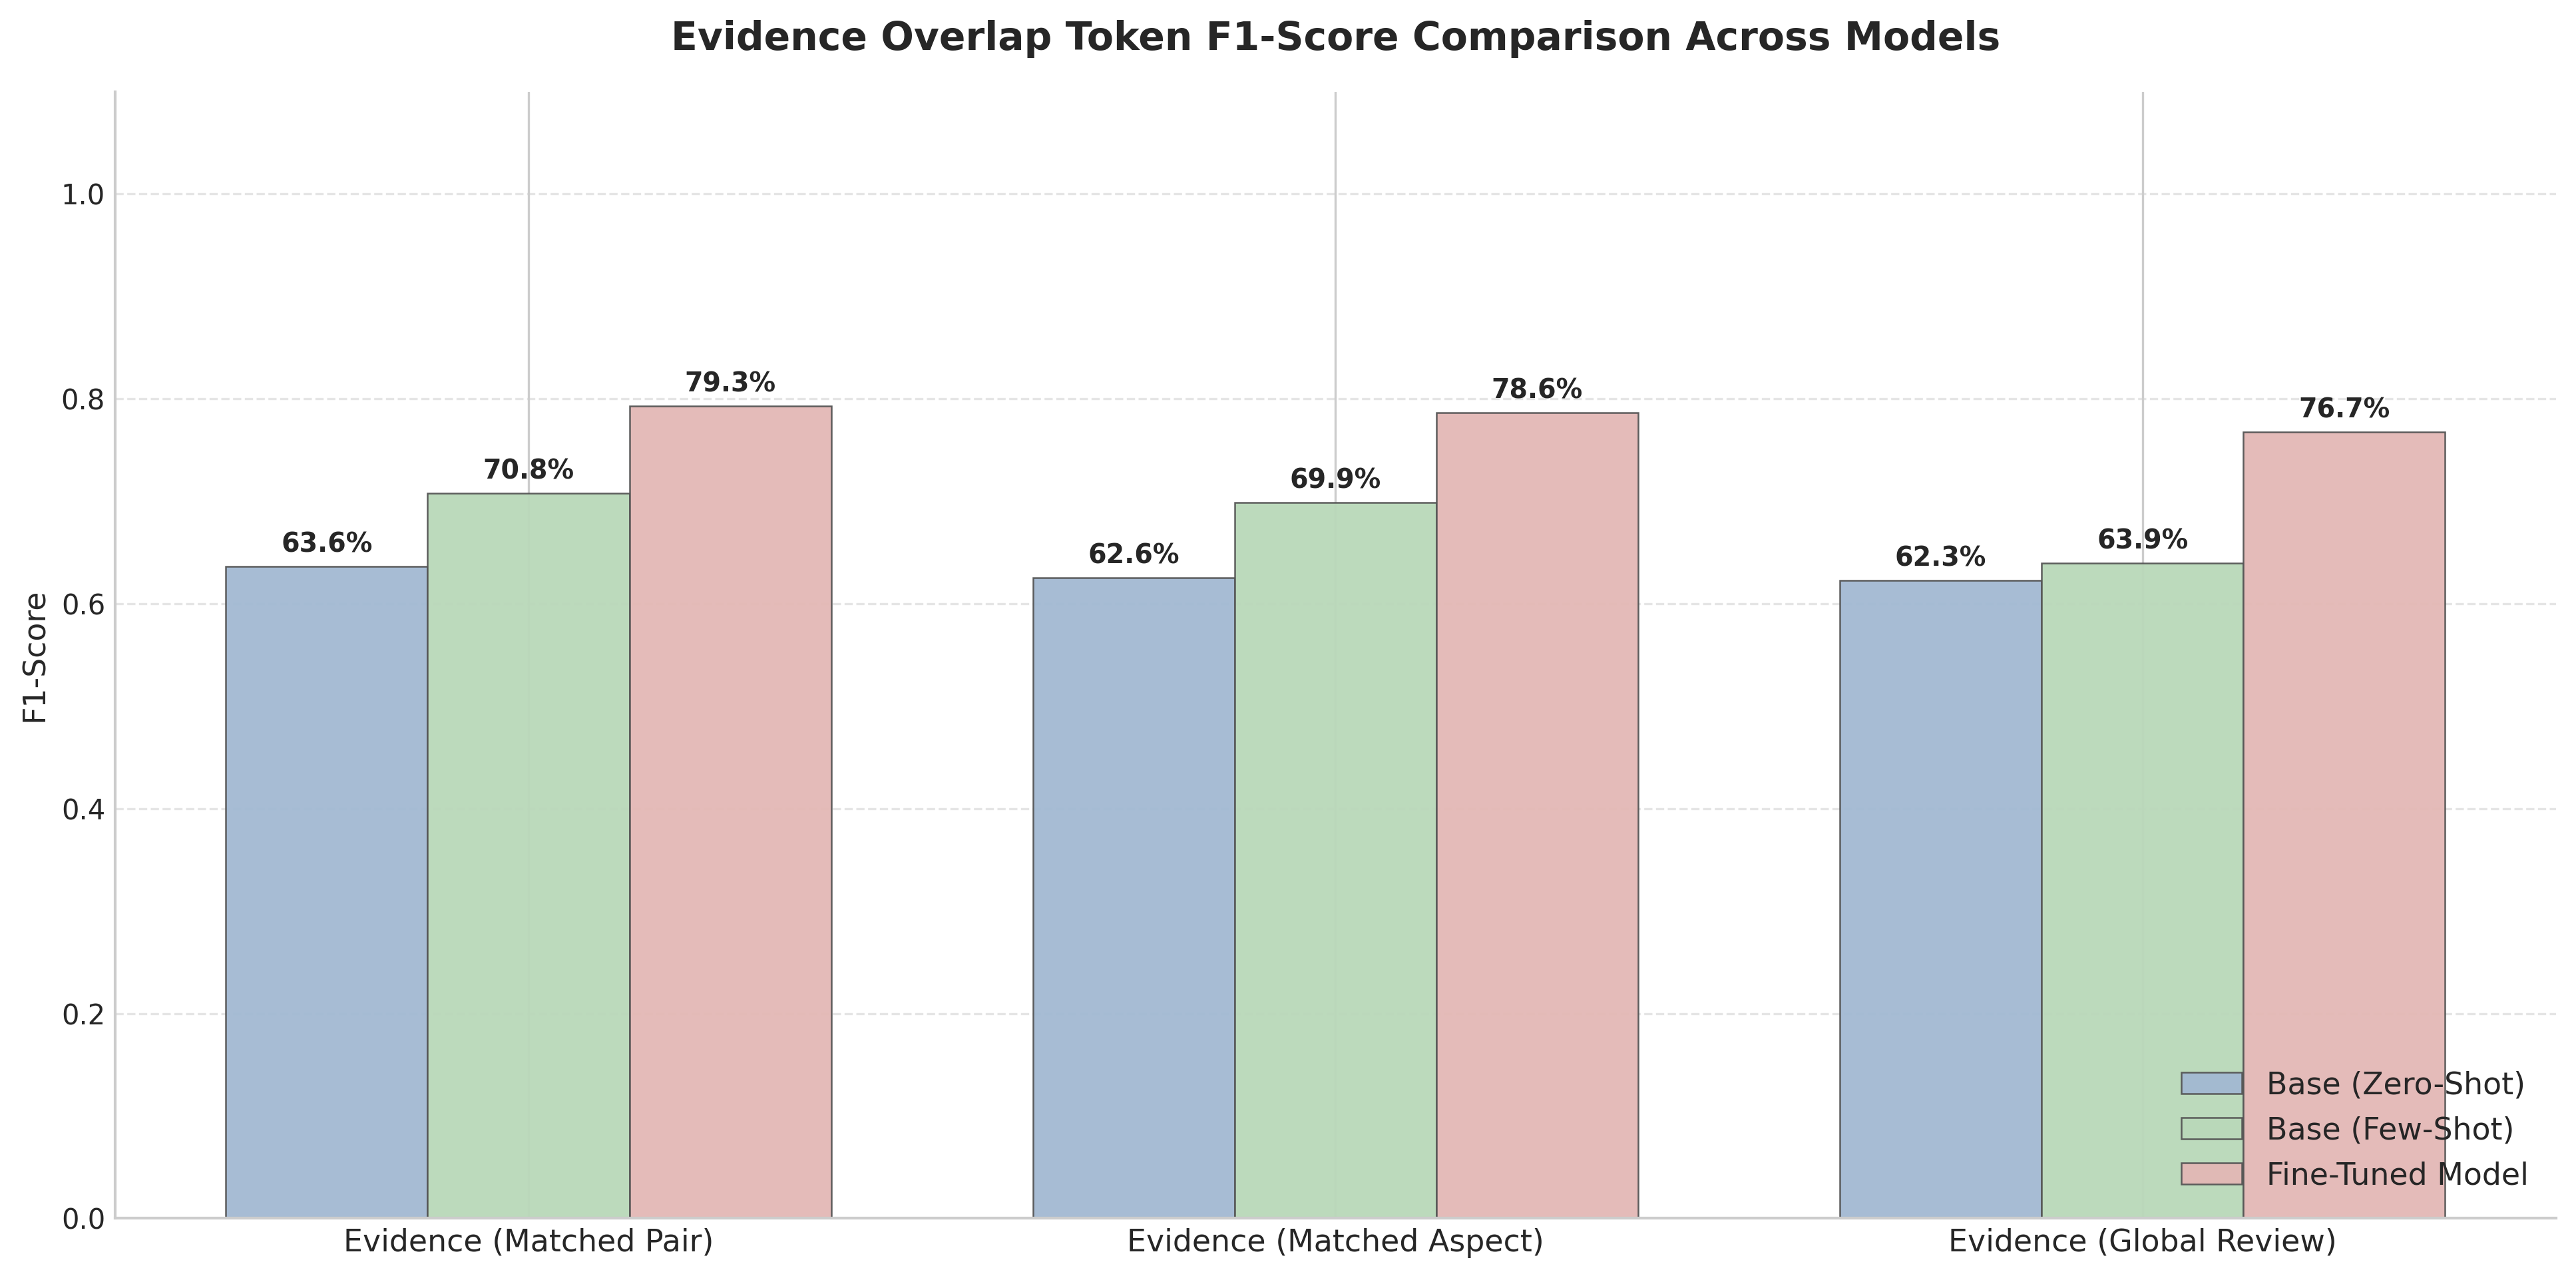

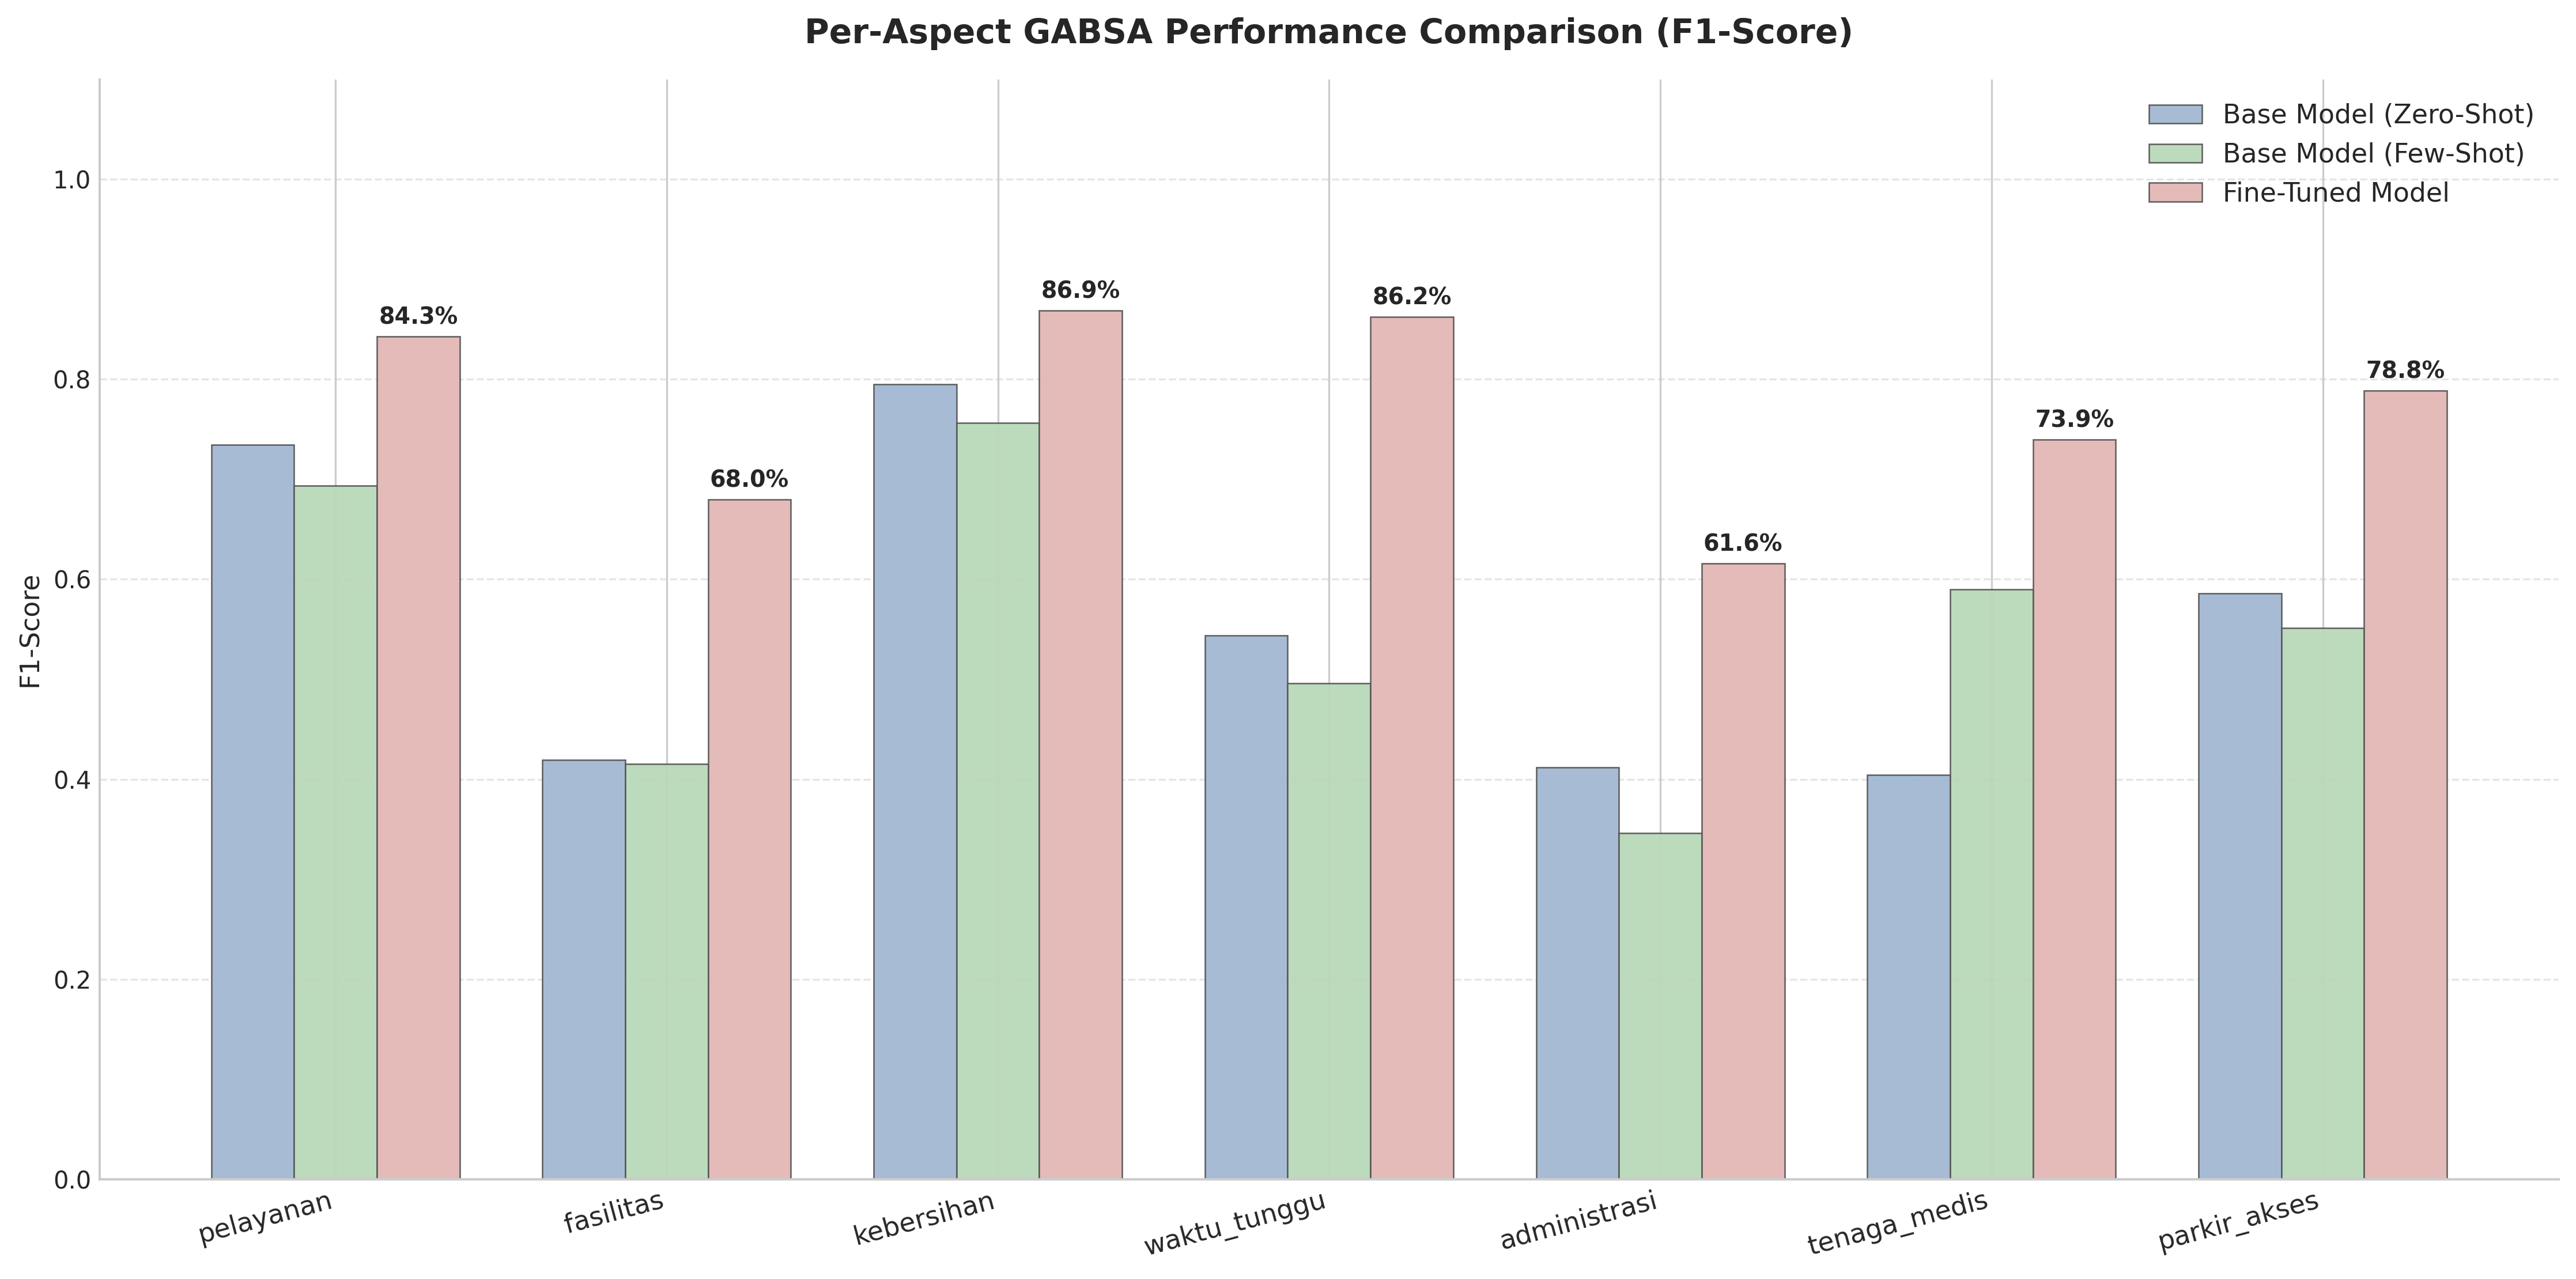

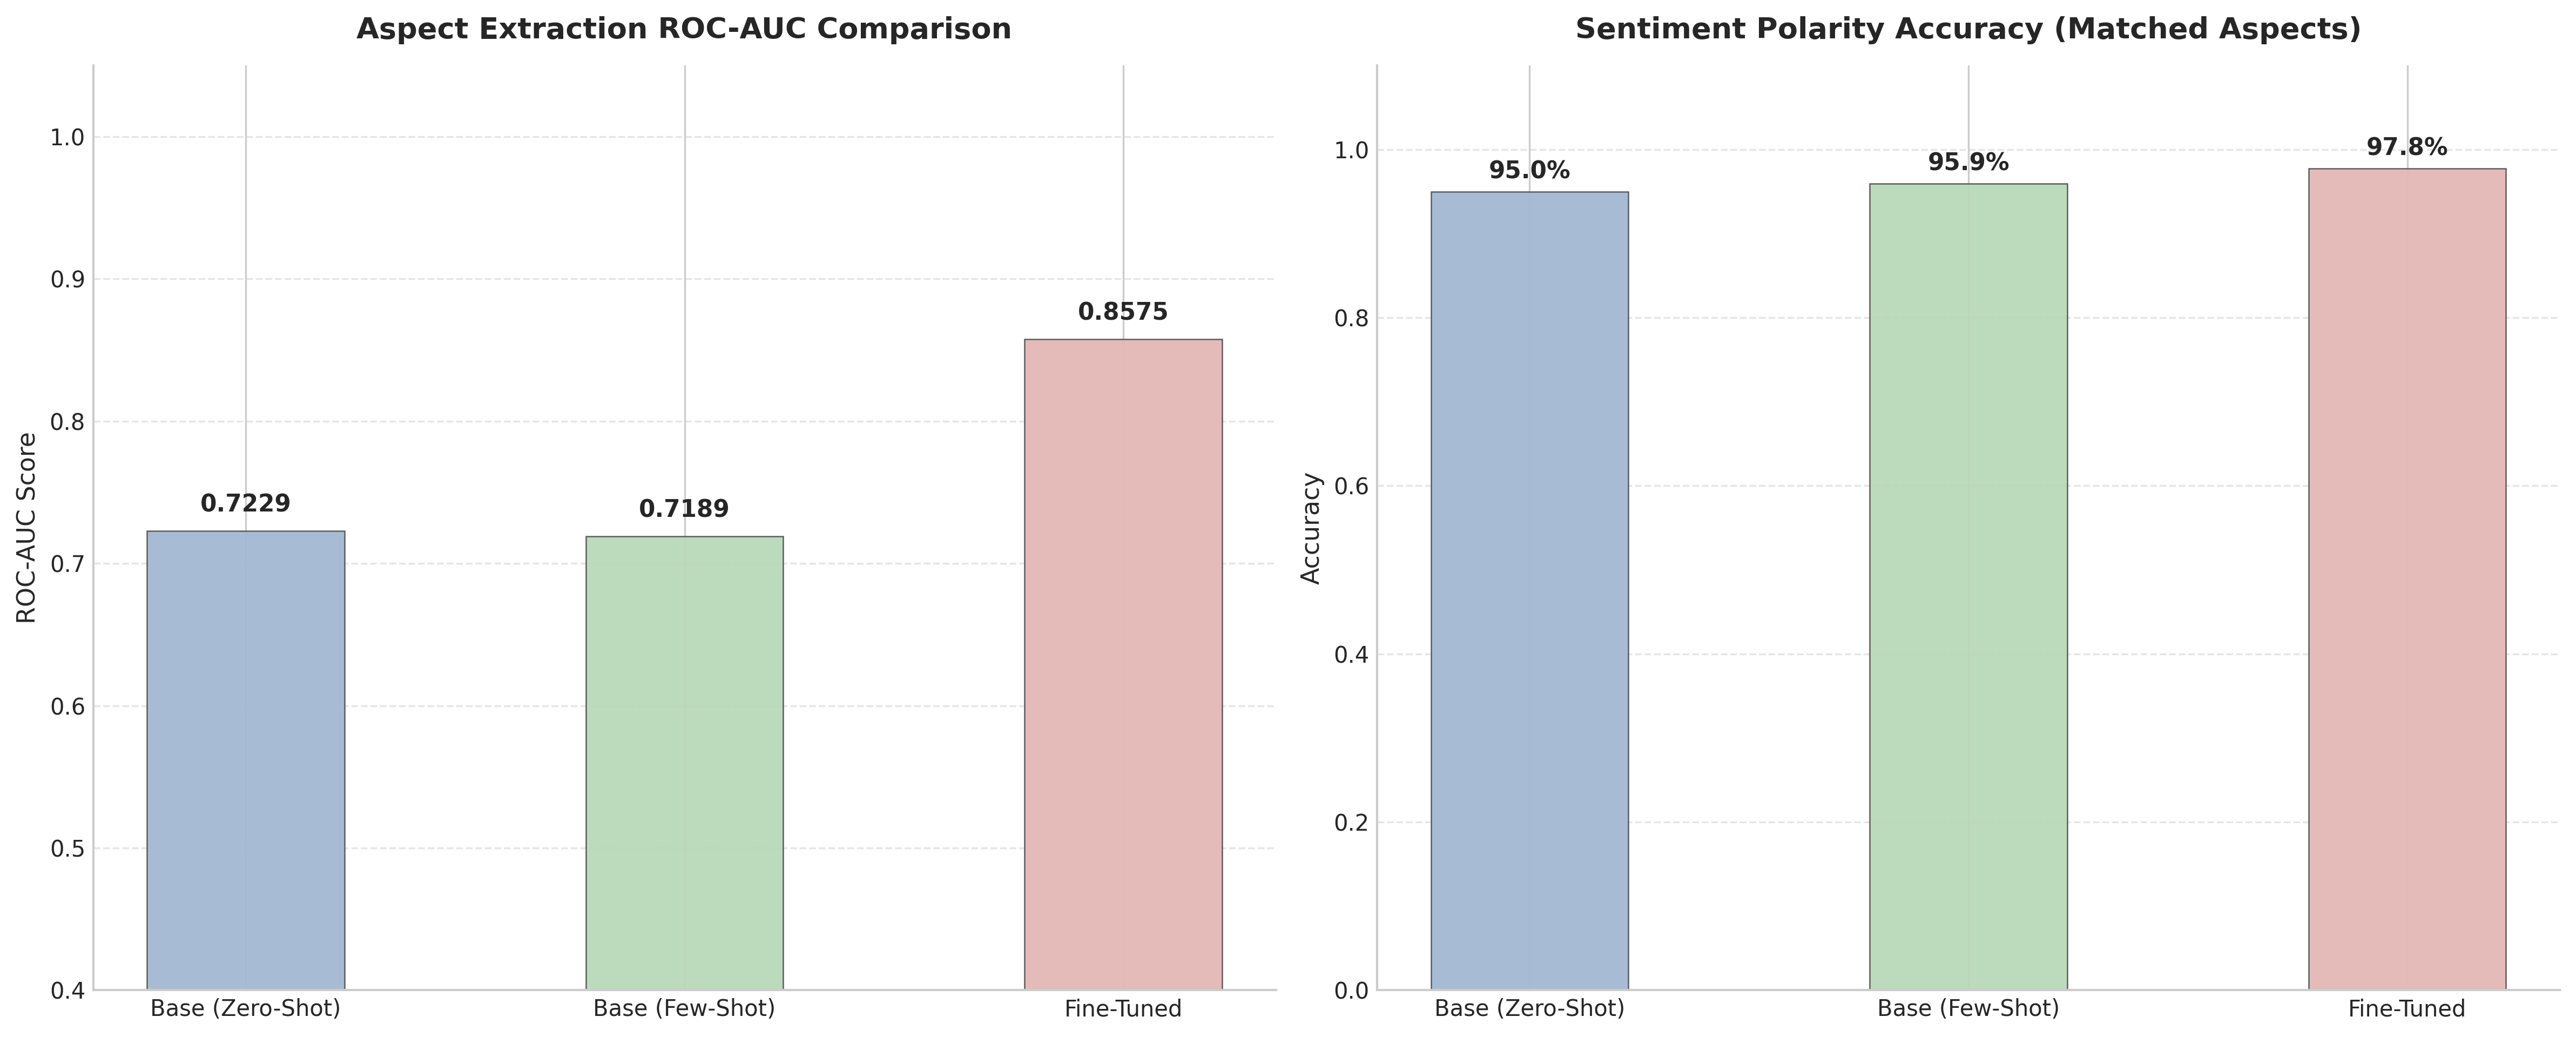

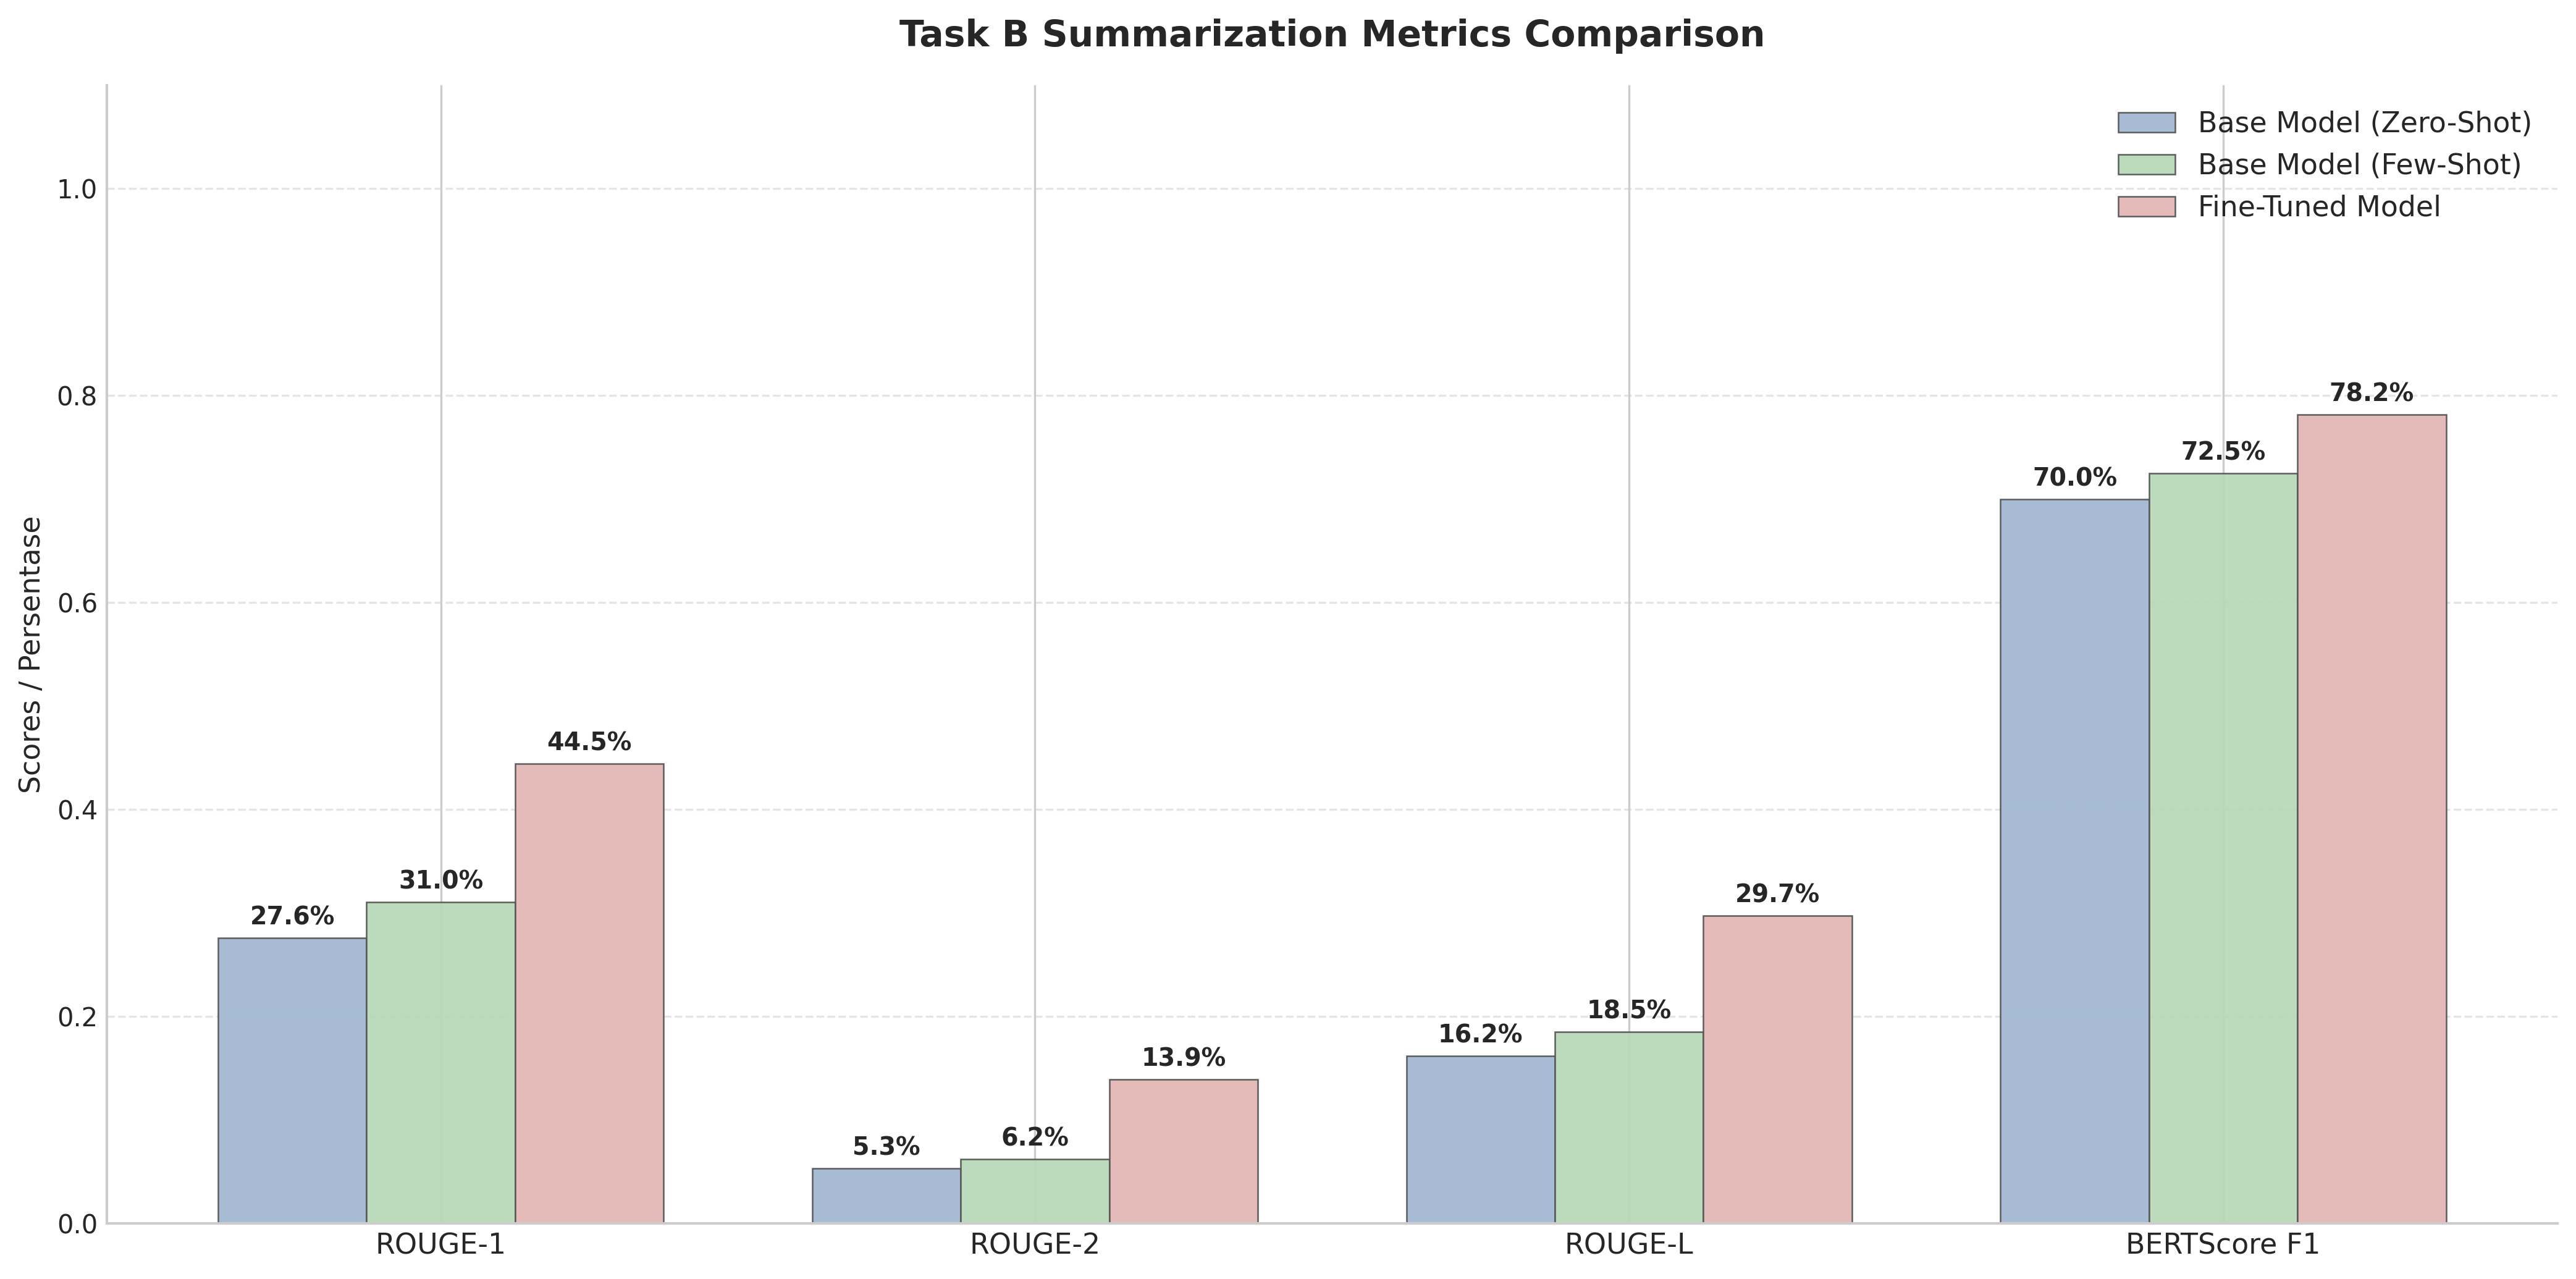

Visualisasi perbandingan performa model berhasil disimpan di folder: evaluation_results/


In [10]:
# Definisikan warna soft pastel untuk visualisasi
color_zero = "#a2b9d2"  # Soft Steel Blue
color_few  = "#b9d8b9"  # Soft Sage Green
color_ft   = "#e3b8b5"  # Soft Dusty Rose
border_color = "#555555"  # Garis tepi tipis

# --- Plot 1: Perbandingan Kepatuhan Format Output JSON Across Models ---
fig, ax = plt.subplots(figsize=(13, 6.5), dpi=300)

models_list = ["Base (Zero-Shot)", "Base (Few-Shot)", "Fine-Tuned"]
x_models = np.arange(len(models_list))
w_json = 0.22

strict_rates = [eval_gabsa_results[m]["strict_json_rate"] for m in models_list]
lenient_rates = [eval_gabsa_results[m]["lenient_json_rate"] for m in models_list]
total_valid_rates = [eval_gabsa_results[m]["total_json_rate"] for m in models_list]
invalid_rates = [eval_gabsa_results[m]["invalid_json_rate"] for m in models_list]

color_strict = "#2b5c8f"   # Deep Navy Blue
color_tot_val = "#70a1d7"  # Medium Sky Blue
color_inv = "#e57373"      # Soft Coral Red

rects_strict = ax.bar(x_models - w_json, strict_rates, w_json, label='Strict JSON Rate (Direct Output)', color=color_strict, edgecolor=border_color, linewidth=0.6, alpha=0.95)
rects_valid = ax.bar(x_models, total_valid_rates, w_json, label='Total Valid JSON Rate (Strict + Lenient)', color=color_tot_val, edgecolor=border_color, linewidth=0.6, alpha=0.95)
rects_invalid = ax.bar(x_models + w_json, invalid_rates, w_json, label='Invalid Format Rate (Failure)', color=color_inv, edgecolor=border_color, linewidth=0.6, alpha=0.95)

ax.set_title('Perbandingan Kepatuhan Output Terhadap Format JSON (Task A - GABSA)', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x_models)
ax.set_xticklabels(models_list, fontsize=11, fontweight='bold')
ax.set_ylabel('Persentase Output (%)', fontsize=11)
ax.set_ylim(0, 1.15)
ax.legend(fontsize=10.5, loc='upper left')
ax.grid(True, linestyle='--', alpha=0.5, axis='y')

for rect in rects_strict:
    h = rect.get_height()
    ax.annotate(f'{h:.2%}', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9.5, fontweight='bold')

for rect in rects_valid:
    h = rect.get_height()
    ax.annotate(f'{h:.2%}', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9.5, fontweight='bold')

for rect in rects_invalid:
    h = rect.get_height()
    ax.annotate(f'{h:.2%}', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9.5, fontweight='bold')

sns.despine(fig)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "comparative_json_compliance.png"), dpi=300)
plt.show()

# --- Plot 2: Perbandingan 3 Jenis Ekstraksi (Aspect vs Sentiment vs Pair F1) ---
fig, ax = plt.subplots(figsize=(14, 7), dpi=300)

x_labels_3ext = ["Aspect Extraction F1", "Sentiment Extraction F1", "Pair Extraction F1"]
base_zero_3ext = [eval_gabsa_results["Base (Zero-Shot)"]["aspect_f1"], eval_gabsa_results["Base (Zero-Shot)"]["sentiment_f1"], eval_gabsa_results["Base (Zero-Shot)"]["pair_f1"]]
base_few_3ext = [eval_gabsa_results["Base (Few-Shot)"]["aspect_f1"], eval_gabsa_results["Base (Few-Shot)"]["sentiment_f1"], eval_gabsa_results["Base (Few-Shot)"]["pair_f1"]]
ft_3ext = [eval_gabsa_results["Fine-Tuned"]["aspect_f1"], eval_gabsa_results["Fine-Tuned"]["sentiment_f1"], eval_gabsa_results["Fine-Tuned"]["pair_f1"]]

x = np.arange(len(x_labels_3ext))
width = 0.25

ax.bar(x - width, base_zero_3ext, width, label='Base (Zero-Shot)', color=color_zero, edgecolor=border_color, linewidth=0.6, alpha=0.95)
ax.bar(x, base_few_3ext, width, label='Base (Few-Shot)', color=color_few, edgecolor=border_color, linewidth=0.6, alpha=0.95)
ax.bar(x + width, ft_3ext, width, label='Fine-Tuned Model', color=color_ft, edgecolor=border_color, linewidth=0.6, alpha=0.95)

ax.set_title('Comparative Performance: 3 Extraction Tasks (F1-Score)', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(x_labels_3ext, fontsize=12)
ax.set_ylabel('F1-Score', fontsize=12)
ax.set_ylim(0, 1.1)
ax.legend(fontsize=11, loc='lower right')
ax.grid(True, linestyle='--', alpha=0.5, axis='y')

for idx in range(len(x_labels_3ext)):
    ax.annotate(f'{base_zero_3ext[idx]:.1%}', xy=(x[idx] - width, base_zero_3ext[idx]), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9.5, fontweight='bold')
    ax.annotate(f'{base_few_3ext[idx]:.1%}', xy=(x[idx], base_few_3ext[idx]), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9.5, fontweight='bold')
    ax.annotate(f'{ft_3ext[idx]:.1%}', xy=(x[idx] + width, ft_3ext[idx]), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9.5, fontweight='bold')

sns.despine(fig)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "comparative_3_extractions_f1.png"), dpi=300)
plt.show()

# --- Plot 3: Distribusi Evidence Token Overlap F1-Score (Fine-Tuned Model) ---
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=300)
ft_ev_global_list = eval_gabsa_results["Fine-Tuned"]["evidence_global_list"]
mean_ev_f1_ft = eval_gabsa_results["Fine-Tuned"]["evidence_global_f1"]

sns.histplot(ft_ev_global_list, kde=True, bins=20, color=color_ft, edgecolor=border_color, linewidth=0.6, ax=ax)
ax.axvline(mean_ev_f1_ft, color='#b22222', linestyle='--', linewidth=2, label=f'Mean F1: {mean_ev_f1_ft:.2%}')
ax.set_title('Distribution of Evidence Token Overlap F1-Score (Fine-Tuned Model - Review Level)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Token Overlap F1-Score', fontsize=11)
ax.set_ylabel('Review Count', fontsize=11)
ax.legend(fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5, axis='y')

sns.despine(fig)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "finetuned_evidence_overlap_distribution.png"), dpi=300)
plt.show()

# --- Plot 4: Komparasi Evidence Overlap Metrics (Matched Pair, Matched Aspect, Global Review) ---
fig, ax = plt.subplots(figsize=(13, 6.5), dpi=300)
x_labels_ev = ["Evidence (Matched Pair)", "Evidence (Matched Aspect)", "Evidence (Global Review)"]
base_zero_ev = [eval_gabsa_results["Base (Zero-Shot)"]["evidence_pair_f1"], eval_gabsa_results["Base (Zero-Shot)"]["evidence_aspect_f1"], eval_gabsa_results["Base (Zero-Shot)"]["evidence_global_f1"]]
base_few_ev = [eval_gabsa_results["Base (Few-Shot)"]["evidence_pair_f1"], eval_gabsa_results["Base (Few-Shot)"]["evidence_aspect_f1"], eval_gabsa_results["Base (Few-Shot)"]["evidence_global_f1"]]
ft_ev = [eval_gabsa_results["Fine-Tuned"]["evidence_pair_f1"], eval_gabsa_results["Fine-Tuned"]["evidence_aspect_f1"], eval_gabsa_results["Fine-Tuned"]["evidence_global_f1"]]

x_ev = np.arange(len(x_labels_ev))
ax.bar(x_ev - width, base_zero_ev, width, label='Base (Zero-Shot)', color=color_zero, edgecolor=border_color, linewidth=0.6, alpha=0.95)
ax.bar(x_ev, base_few_ev, width, label='Base (Few-Shot)', color=color_few, edgecolor=border_color, linewidth=0.6, alpha=0.95)
ax.bar(x_ev + width, ft_ev, width, label='Fine-Tuned Model', color=color_ft, edgecolor=border_color, linewidth=0.6, alpha=0.95)

ax.set_title('Evidence Overlap Token F1-Score Comparison Across Models', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x_ev)
ax.set_xticklabels(x_labels_ev, fontsize=11)
ax.set_ylabel('F1-Score', fontsize=11)
ax.set_ylim(0, 1.1)
ax.legend(fontsize=11, loc='lower right')
ax.grid(True, linestyle='--', alpha=0.5, axis='y')

for idx in range(len(x_labels_ev)):
    ax.annotate(f'{base_zero_ev[idx]:.1%}', xy=(x_ev[idx] - width, base_zero_ev[idx]), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9.5, fontweight='bold')
    ax.annotate(f'{base_few_ev[idx]:.1%}', xy=(x_ev[idx], base_few_ev[idx]), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9.5, fontweight='bold')
    ax.annotate(f'{ft_ev[idx]:.1%}', xy=(x_ev[idx] + width, ft_ev[idx]), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9.5, fontweight='bold')

sns.despine(fig)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "comparative_evidence_overlap_metrics.png"), dpi=300)
plt.show()

# --- Plot 5: Per-Aspect Category F1-Score ---
aspect_list = ["pelayanan", "fasilitas", "kebersihan", "waktu_tunggu", "administrasi", "tenaga_medis", "parkir_akses"]
x_idx = np.arange(len(aspect_list))

fig, ax = plt.subplots(figsize=(15, 7.5), dpi=300)

base_zero_asp = [eval_gabsa_results["Base (Zero-Shot)"]["per_aspect_f1"][a] for a in aspect_list]
base_few_asp = [eval_gabsa_results["Base (Few-Shot)"]["per_aspect_f1"][a] for a in aspect_list]
ft_asp = [eval_gabsa_results["Fine-Tuned"]["per_aspect_f1"][a] for a in aspect_list]

ax.bar(x_idx - width, base_zero_asp, width, label='Base Model (Zero-Shot)', color=color_zero, edgecolor=border_color, linewidth=0.6, alpha=0.95)
ax.bar(x_idx, base_few_asp, width, label='Base Model (Few-Shot)', color=color_few, edgecolor=border_color, linewidth=0.6, alpha=0.95)
ax.bar(x_idx + width, ft_asp, width, label='Fine-Tuned Model', color=color_ft, edgecolor=border_color, linewidth=0.6, alpha=0.95)

ax.set_title('Per-Aspect GABSA Performance Comparison (F1-Score)', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x_idx)
ax.set_xticklabels(aspect_list, rotation=15, ha='right', fontsize=11)
ax.set_ylabel('F1-Score', fontsize=11)
ax.set_ylim(0, 1.1)
ax.legend(fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5, axis='y')

for idx, val in enumerate(ft_asp):
    ax.annotate(f'{val:.1%}', xy=(x_idx[idx] + width, val), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9.5, fontweight='bold')

sns.despine(fig)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "comparative_aspect_f1_scores.png"), dpi=300)
plt.show()

# --- Plot 6: Aspect Extraction ROC-AUC & Sentiment Accuracy ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), dpi=300)

models_list = ["Base (Zero-Shot)", "Base (Few-Shot)", "Fine-Tuned"]
roc_aucs = [eval_gabsa_results[m]["roc_auc"] for m in models_list]
sent_accs = [eval_gabsa_results[m]["sentiment_accuracy"] for m in models_list]

axes[0].bar(models_list, roc_aucs, color=[color_zero, color_few, color_ft], width=0.45, edgecolor=border_color, linewidth=0.6, alpha=0.95)
axes[0].set_title('Aspect Extraction ROC-AUC Comparison', fontsize=13, fontweight='bold', pad=12)
axes[0].set_ylabel('ROC-AUC Score', fontsize=11)
axes[0].set_ylim(0.4, 1.05)
axes[0].grid(True, linestyle='--', alpha=0.5, axis='y')
for idx, val in enumerate(roc_aucs):
    axes[0].text(idx, val + 0.01, f'{val:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=10.5)

axes[1].bar(models_list, sent_accs, color=[color_zero, color_few, color_ft], width=0.45, edgecolor=border_color, linewidth=0.6, alpha=0.95)
axes[1].set_title('Sentiment Polarity Accuracy (Matched Aspects)', fontsize=13, fontweight='bold', pad=12)
axes[1].set_ylabel('Accuracy', fontsize=11)
axes[1].set_ylim(0, 1.1)
axes[1].grid(True, linestyle='--', alpha=0.5, axis='y')
for idx, val in enumerate(sent_accs):
    axes[1].text(idx, val + 0.01, f'{val:.1%}', ha='center', va='bottom', fontweight='bold', fontsize=10.5)

sns.despine(fig)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "comparative_auc_sentiment_accuracy.png"), dpi=300)
plt.show()

# --- Plot 7: Summarization Metrics Comparison ---
metrics_summary = ['ROUGE-1', 'ROUGE-2', 'ROUGE-L', 'BERTScore F1']
base_zero_sum = [eval_summary_results["Base (Zero-Shot)"]["rouge1"], eval_summary_results["Base (Zero-Shot)"]["rouge2"], eval_summary_results["Base (Zero-Shot)"]["rougeL"], eval_summary_results["Base (Zero-Shot)"]["bert_f1"]]
base_few_sum = [eval_summary_results["Base (Few-Shot)"]["rouge1"], eval_summary_results["Base (Few-Shot)"]["rouge2"], eval_summary_results["Base (Few-Shot)"]["rougeL"], eval_summary_results["Base (Few-Shot)"]["bert_f1"]]
ft_sum = [eval_summary_results["Fine-Tuned"]["rouge1"], eval_summary_results["Fine-Tuned"]["rouge2"], eval_summary_results["Fine-Tuned"]["rougeL"], eval_summary_results["Fine-Tuned"]["bert_f1"]]

x_sum = np.arange(len(metrics_summary))

fig, ax = plt.subplots(figsize=(14, 7), dpi=300)
ax.bar(x_sum - width, base_zero_sum, width, label='Base Model (Zero-Shot)', color=color_zero, edgecolor=border_color, linewidth=0.6, alpha=0.95)
ax.bar(x_sum, base_few_sum, width, label='Base Model (Few-Shot)', color=color_few, edgecolor=border_color, linewidth=0.6, alpha=0.95)
ax.bar(x_sum + width, ft_sum, width, label='Fine-Tuned Model', color=color_ft, edgecolor=border_color, linewidth=0.6, alpha=0.95)

ax.set_title('Task B Summarization Metrics Comparison', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x_sum)
ax.set_xticklabels(metrics_summary, fontsize=11)
ax.set_ylabel('Scores / Persentase', fontsize=11)
ax.set_ylim(0, 1.1)
ax.legend(fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5, axis='y')

# UPDATE: Semua bar sekarang menampilkan nilai dalam format persentase (e.g., 75.4%)
for idx in range(len(metrics_summary)):
    ax.annotate(f'{base_zero_sum[idx]:.1%}', xy=(x_sum[idx] - width, base_zero_sum[idx]), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9.5, fontweight='bold')
    ax.annotate(f'{base_few_sum[idx]:.1%}', xy=(x_sum[idx], base_few_sum[idx]), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9.5, fontweight='bold')
    ax.annotate(f'{ft_sum[idx]:.1%}', xy=(x_sum[idx] + width, ft_sum[idx]), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9.5, fontweight='bold')

sns.despine(fig)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "comparative_summarization_metrics.png"), dpi=300)
plt.show()

print("Visualisasi perbandingan performa model berhasil disimpan di folder:", OUTPUT_DIR)


## 9. Qualitative Generation Samples Check & Format Compliance Summary
Menampilkan contoh keluaran hasil prediksi model-model secara kualitatif berdampingan dengan ground truth untuk diinspeksi secara manual, serta rangkuman analisis kepatuhan format JSON.

### Ringkasan Analisis Kepatuhan Format Output JSON:
1. **Base Model (Zero-Shot)**: Cenderung menghasilkan teks pengantar percakapan (*conversational preamble* seperti *"Berikut adalah hasil ekstraksi..."*) sebelum menyajikan data JSON. Hal ini menyebabkan kepatuhan *Strict* rendah (**4.06%**), namun **94.16%** output dapat dipulihkan melalui parsing *Lenient* (Total Valid **98.22%**).
2. **Base Model (Few-Shot)**: Pemberian contoh 2-shot secara efektif memandu model untuk memformat keluaran sebagai JSON murni tanpa percakapan pengantar (*Strict Rate* melonjak ke **89.75%**). Namun, model mengalami tingkat kegagalan format (*Invalid Rate*) sebesar **8.98%** akibat kemunculan sintaks JSON tidak lengkap atau terpotong pada ulasan yang panjang/kompleks.
3. **Fine-Tuned Model**: Mencapai kepatuhan format JSON sempurna (**100.00% Strict Rate** dan **0.00% Invalid Rate**). Proses *LoRA multi-task fine-tuning* berhasil mengunci *schema adherence* model sehingga menghasilkan sintaks JSON valid secara konsisten tanpa membutuhkan *prompt engineering* atau pemulihan *lenient*.


In [9]:
# Load prediction files untuk qualitative print
gabsa_zero_preds = load_jsonl(GABSA_PRED_ZERO)
gabsa_few_preds = load_jsonl(GABSA_PRED_FEW)
gabsa_ft_preds = load_jsonl(GABSA_PRED_FT)

summary_zero_preds = load_jsonl(SUMMARY_PRED_ZERO)
summary_few_preds = load_jsonl(SUMMARY_PRED_FEW)
summary_ft_preds = load_jsonl(SUMMARY_PRED_FT)

print("=== CONTOH INFERENSI KUALITATIF - TASK A (GABSA) ===")
print(f"Teks Ulasan Asli:\n'{gabsa_test_data[0]['text_clean']}'\n")
print(f"Ground Truth:\n{json.dumps(gabsa_test_data[0]['labels'], indent=2)}\n")
print(f"Prediksi Base Model (Zero-Shot):\n{gabsa_zero_preds[0].get('prediction_raw', '')}\n")
print(f"Prediksi Base Model (Few-Shot):\n{gabsa_few_preds[0].get('prediction_raw', '')}\n")
pred_ft_gabsa = gabsa_ft_preds[0].get('prediction_raw', json.dumps(gabsa_ft_preds[0].get('predicted_labels', []), indent=2))
print(f"Prediksi Fine-Tuned Model:\n{pred_ft_gabsa}\n")
print("="*80 + "\n")

print("=== CONTOH INFERENSI KUALITATIF - TASK B (SUMMARIZATION) ===")
print(f"Statistik Ulasan (Input):\n{summary_test_data[0]['input_stats']}\n")
print(f"Acuan Ringkasan Manusia (Ground Truth):\n{summary_test_data[0]['target_summary']}\n")
print(f"Generasi Base Model (Zero-Shot):\n{summary_zero_preds[0].get('prediction_raw', '')}\n")
print(f"Generasi Base Model (Few-Shot):\n{summary_few_preds[0].get('prediction_raw', '')}\n")
pred_ft_summary = summary_ft_preds[0].get('prediction_raw', summary_ft_preds[0].get('predicted_summary', ''))
print(f"Generasi Fine-Tuned Model:\n{pred_ft_summary}\n")


=== CONTOH INFERENSI KUALITATIF - TASK A (GABSA) ===
Teks Ulasan Asli:
'saya periksa tht dirumah sakit ini, mahal sekali tapi tidak dengan fasilitasnya. tidak ada pemeriksaan yang dijelaskan secara detail pada layar monitor, dokter pun juga tidak menjelaskan secara detail kondisi pasien, hanya diam dan bicara seperlunya. intinya tidak seperti klinik tht lainnya, tidak diperlihatkan kondisi kuping kita pada layar monitor. hanya dikasih obat tetes kuping lalu disuruh tunggu di depan buat tebus obat. sangat tidak memuaskan sekali. tolong diperbaiki pelayannya.'

Ground Truth:
[
  {
    "aspect": "tenaga_medis",
    "sentiment": "negatif",
    "evidence": "tidak ada pemeriksaan yang dijelaskan secara detail pada layar monitor, dokter pun juga tidak menjelaskan secara detail kondisi pasien, hanya diam dan bicara seperlunya"
  },
  {
    "aspect": "administrasi",
    "sentiment": "negatif",
    "evidence": "tidak diperlihatkan kondisi kuping kita pada layar monitor. hanya dikasih obat tetes 